# Расчёт проточной части газовой турбины — по порядку книги
**Михальцев В.Е., Моляков В.Д. «Теория и проектирование газовой турбины», ч. 1** (МГТУ им. Баумана, 2006),
порядок расчёта п. 1–153 (стр. 84–93), профилирование — гл. 7, решётки — гл. 8.

**Как пользоваться**
1. Исходные данные цикла (T\*г, p\*г, расход, p_т …) берутся из `Turbinis-Cycle` автоматически (раздел 1). Меняются там.
2. Все **выбираемые** величины книги собраны в разделе 2 — **меняйте только эту ячейку**. Рядом с каждой — номер пункта и рекомендация книги.
   Величины, задаваемые по ступеням, — списки `[ст. 1, ст. 2, …, ст. z]`, длина списка = `z`.
3. *Kernel → Restart & Run All*. Разделы 3–9 идут в порядке книги; в конце — контроль и сводка.

**Чем расчёт отличается от «ручного» по книге** (это видно в разделе 6):
* степень реактивности каждой ступени — по рекомендации книги: ρ_ср по l/D, у корня ρ ≥ 0,05 (стр. 58); угол выхода α₂ получается в расчёте и проверяется по стр. 38 (п. 99: «при отклонении α₂ … параметры пересчитываются»);
* частота вращения n уточняется итерацией: площадь A_т за последней ступенью (п. 9) после расчёта ступеней получается другой → пересчёт n (п. 11);
* расход воздуха подбирается так, чтобы мощность на валу была равна заданной в цикле (у ступеней книги КПД иной, чем принят в цикле).

Вариант по умолчанию: π\*к = 11, **z = 3, лопатки 17,0…22,7 мм** (СА1 / РК1 / СА2 / РК2 / СА3 / РК3 = 17,0 / 17,0 / 17,2 / 19,4 / 19,6 / 22,7 мм), длины растут по ходу газа. Степень реактивности — **по рекомендациям книги** (ρ_ср по l/D, у корня ρ ≥ 0,05, стр. 58); π ступеней 2,21 / 2,17 / 2,39 (допуск 1,8…2,4); α₂ 2-й и 3-й ступеней в допусках стр. 38. **Отступления:** α₁ 1-й ступени 9,25° и 2-й 11° (книга для малых турбин 11…14°, стр. 35) — ради длинных лопаток; закрутка за 1-й ступенью (α₂ ≈ 22°, допуск ослаблен — `α2_ст1`); u_т ≈ 385 м/с (σ_л = 290 МПа) — выше п. 6.2 цикла, но в пределах книги (300…400 м/с, стр. 59).
Прежние варианты (строго по книге l_c1 ≈ 6,9 мм, z = 4 и др.) — в истории git, см. `Ограничения_проекта.md`, разд. 8.

In [1]:
%matplotlib inline
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for _p in (Path.cwd(), Path.cwd() / "Turbinis-Calc"):
    if (_p / "cycle_link.py").exists():
        sys.path.insert(0, str(_p))
from cycle_link import load_cycle

Ц = load_cycle()  # выполняет блокнот Turbinis-Cycle и возвращает его переменные

## 1. Исходные данные из цикла
Задаются в `Turbinis-Cycle` (здесь не меняются). Вариант книги «задано статическое давление за турбиной p_т».

In [2]:
R = Ц["R"]  # газовая постоянная, Дж/(кг·К)
calc_cp = Ц["calc_cp_kerosene"]  # средняя c_p продуктов сгорания керосина (методичка цикла)
р = Ц["р"]  # результаты цикла в выбранной точке

π_к = float(Ц["π_к_выб"])  # степень повышения давления компрессора
α_г = float(р["α"])  # коэффициент избытка воздуха
T_г_полн = float(Ц["T_г_полн"])  # T*г - температура газа перед турбиной, К
p_г_полн = Ц["σ_г"] * Ц["σ_вх"] * Ц["p_а_полн"] * π_к  # p*г = σ_г σ_вх p*в π*к, Па
p_т = Ц["π_с"] * Ц["p_а"]  # p_т - статическое давление за турбиной, Па
G_в = float(Ц["G_в_выб"])  # расход воздуха (первое приближение), кг/с
g_т = float(р["g_т"])  # G_т/G_в = (1 + g_m)(1 - g_ут - g_охл)
охлаждение_лопаток = bool(Ц["охлаждение_лопаток"])  # в цикле: T*г > 1250 К -> лопатки 1-й ступени охлаждаются
g_охл = float(Ц["g_охл"])  # отбор на охлаждение (лопатки при T*г > 1250 К, иначе диски и корпус)
g_воз = float(Ц["g_воз"])  # часть охлаждающего воздуха, возвращаемая в проточную часть за 1-й ступенью
G_c1 = G_в * g_т  # расход через СА 1-й ступени, кг/с
G_л_ост = G_в * (g_т + g_воз)  # расход через ступени 2...z, кг/с
η_м = float(Ц["η_м_тур"])  # механический КПД (п. 152)
η_р = float(Ц["η_р"])  # КПД редуктора
L_к = float(р["L_к"])  # работа компрессора, Дж/кг
N_зад = float(Ц["N_зад"])  # мощность на валу, Вт
η_т_полн_цикл = float(р["η_т"])  # η*т, принятый в цикле
N_т_цикл = G_в * р["L_т"] * (g_т + g_воз) * η_м  # мощность турбины в цикле, Вт

табл_исх = pd.DataFrame(
    [
        ("π*к - степень повышения давления компрессора", "-", π_к),
        ("T*г - температура газа перед турбиной", "К", T_г_полн),
        ("p*г - давление газа перед турбиной", "кПа", p_г_полн / 1e3),
        ("p_т - статическое давление за турбиной", "кПа", p_т / 1e3),
        ("G_в - расход воздуха по циклу", "кг/с", G_в),
        ("G_c1 - расход газа через СА 1-й ступени", "кг/с", G_c1),
        ("охлаждение лопаток 1-й ступени (T*г > 1250 К)", "-", "да" if охлаждение_лопаток else "нет"),
        ("g_охл - отбор воздуха на охлаждение", "%", g_охл * 100),
        ("g_воз - возврат охлаждающего воздуха за 1-й ступенью", "%", g_воз * 100),
        ("α - коэффициент избытка воздуха", "-", α_г),
        ("η_м - механический КПД", "-", η_м),
        ("η_р - КПД редуктора", "-", η_р),
        ("L_к - работа компрессора", "кДж/кг", L_к / 1e3),
        ("N_в - мощность на валу", "кВт", N_зад / 1e3),
        ("η*т - КПД турбины, принятый в цикле", "-", η_т_полн_цикл),
    ],
    columns=["величина", "ед.", "значение"],
)
табл_исх.style.format({"значение": lambda v: v if isinstance(v, str) else f"{v:.4g}"}).hide(axis="index")

величина,ед.,значение
π*к - степень повышения давления компрессора,-,11
T*г - температура газа перед турбиной,К,1250
p*г - давление газа перед турбиной,кПа,1048
p_т - статическое давление за турбиной,кПа,106.4
G_в - расход воздуха по циклу,кг/с,0.5889
G_c1 - расход газа через СА 1-й ступени,кг/с,0.5856
охлаждение лопаток 1-й ступени (T*г > 1250 К),-,нет
g_охл - отбор воздуха на охлаждение,%,1.5
g_воз - возврат охлаждающего воздуха за 1-й ступенью,%,0.9
α - коэффициент избытка воздуха,-,3.973


## 2. Выбираемые параметры — **меняйте только эту ячейку**
Номер пункта — по порядку расчёта книги (стр. 84–93). Списки — по ступеням `[ст. 1, …, ст. z]`.

In [3]:
# Источники: [1] Михальцев В.Е., Моляков В.Д. Теория и проектирование газовой турбины. Ч. 1. - МГТУ им. Баумана, 2006;
#            [2] Михальцев В.Е. Расчёт параметров цикла при проектировании ГТУ (методичка, Turbinis-Cycle);
#            [3] Honeywell TPE331: the growth and evolution. Над каждой выбираемой величиной - диапазон и страница.
# ======================= Частота вращения (п. 1-12) =======================
# [1] стр. 45: лопаточный КПД транспортных ГТД 0,88...0,92
η_л_ожид = 0.90  # п. 5   лопаточный КПД турбины для оценки T_т (задаётся)
# [1] стр. 56: транспортные ГТД c_т = 120...200 м/с; из цикла (M_т, [2] стр. 17)
c_та = float(Ц["c_т"])  # п. 8   осевая скорость за турбиной, м/с - первое приближение (из цикла), дальше уточняется
# [1] стр. 57: 120...200 МПа, особо напряжённые до 300 МПа; [2] стр. 49: авиационные > 300 МПа
σ_л = 290.0  # п. 10  напряжение растяжения в РЛ, МПа -> u_т ≈ 385 м/с (книга: компактные ГТД 300...400 м/с, стр. 59).
#              В цикле (п. 6.2) u_т = 350 м/с -> float(Ц["σ_л_62"]) ≈ 239 МПа; больше u - выше u/c0 ступеней при ρ по книге
# [1] стр. 56: k_n ≈ 6,8·10^-6; стр. 57: (6...7)·10^-6
k_n = float(Ц["K_n"])  # п. 11  коэффициент формы лопатки, ~6,8e-6 (стр. 56)

# ============ Основные размеры многоступенчатой турбины (п. 45-69) ============
# [1] стр. 58: l_т/D_т = 1/4...1/3,5 (иногда до 1/3)
l_т_D_т = float(Ц["l_т_to_D_т"])  # п. 45  l_т/D_т последней ступени (книга: <= 1/3,5...1/3)
# [1] п. 54, стр. 87: по формуле; принято 3 (π ступени 1,8...2,4 - требование проекта)
z = 3  # п. 54  принятое число ступеней (формула п. 54 - только для сравнения)
# [1] п. 48, стр. 87: выбирается; D1 < D_т удлиняет лопатку 1-й ступени (решение проекта)
D_ст = [0.67, 1.0, 1.0]  # п. 48  средний диаметр ступени D/D_т (последняя = 1). Меньше D -> длиннее лопатка, но меньше u
# [1] стр. 58: (u/c0) = 0,55...0,6 при ρ_ср = 0,25...0,45
y0 = 0.54  # п. 51  оптимальное u/c0 (для оценки z по п. 54)
# [1] п. 53, 131, стр. 87, 92: выбирается, чисел книга не даёт
μ = 0.9  # п. 53, 131  коэффициент использования скорости c2 следующей ступенью
# [1] п. 55: распределение H0 по ступеням; π ступени 1,8...2,4 (требование проекта)
π_веса = [0.91, 0.89, 1.0]  # п. 55  распределение теплоперепада: ln(p*0/p2) ступени ~ вес (последняя - по p_т);
#                               1-я ступень легче (длинная лопатка), 2-я чуть легче 3-й (α2 2-й ступени >= 70°)
# [1] стр. 35: обычно > 16...17°, малые турбины 11...14°; ОТСТУПЛЕНИЕ: 1-я ступень 9,25°, 2-я 11° - ради длинных лопаток
α1_ст = [9.25, 11.0, 19.0]  # п. 58  угол выхода из СА, град: меньше α1 -> меньше c1a = c1·sin α1 -> длиннее лопатка
# [1] стр. 61: одноступенчатые СА 2...2,5, РК 2,5...3; ТВД 1...1,5 и 1,5...2
lb_c, lb_л = 2.25, 2.75  # п. 65-66  удлинение l/b_a СА и РК (одноступенчатые: 2...2,5 и 2,5...3, стр. 61)
# [1] стр. 62: δ_a/b_a = 0,20...0,25
δа_к_ba = 0.22  # п. 67-68  осевой зазор δ_a/b_a = 0,20...0,25 (стр. 62)

# ====================== Ступень (п. 70-129) ======================
# [1] стр. 34: φ = 0,95...0,97
φ = 0.97  # п. 37, 73  коэффициент скорости СА: 0,95...0,97 (стр. 34)
# [1] стр. 37: чисел не даёт; типично 0,92...0,96, проверяется по решёткам (раздел 11)
ψ = 0.96  # п. 89  коэффициент скорости РК: книга чисел не даёт (стр. 37: зависит от формы канала, угла поворота, ρ); типично 0,92...0,96
# [1] стр. 38: промежуточные ступени α2 = 70...90°
α2_пром = (70.0, 90.0)  # п. 99  допустимый угол выхода α2 промежуточных ступеней, град (стр. 38)
# [1] стр. 38: последняя ступень α2 = 80...90°
α2_посл = (80.0, 90.0)  # п. 99  то же для последней ступени (стр. 38); 90° - осевой выход
# [1] стр. 38: 70...90°; ослаблено по решению проекта
α2_ст1 = (20.0, 90.0)  # допуск α2 1-й ступени - ОСЛАБЛЕН относительно стр. 38 (70...90°) по решению: закрутка за 1-й ступенью
#                         ради длинной лопатки l_c1; её энергию использует 2-я ступень (μ). Для книжного варианта - (70.0, 90.0)
# [1] п. 96, стр. 89: c2a задаётся, чисел нет; c2a > c1a - стр. 62
κ_ст = [1.38, 1.12, 1.15]  # п. 96  (κ1, κ2 > 1 - РЛ не длиннее СЛ следующей ступени)  c2a = κ·c1a. У последней ступени κ > 1: выше c_т -> меньше A_т -> больше n
# [1] стр. 63: δ/l = 0,007...0,01; меньше - с сотовыми вставками
δ_отн = 0.005  # п. 113  радиальный зазор δ_л/l (книга: 0,007...0,01, стр. 63; с сотовыми вставками меньше)
# [1] стр. 12: с сотовыми вставками ≤ 0,2 мм
δ_мин = 0.2e-3  # п. 113  наименьший радиальный зазор, м (сотовые вставки <= 0,2 мм, стр. 12)
# [1] стр. 45: обычно полный подвод ε = 1
ε_парц = 1.0  # п. 119  степень парциальности (полный подвод)

# ============ Профилирование по радиусу (гл. 7) ============
# [1] разд. 7.3: Γ = const или α1 = const
закон_ст = ["α1", "α1", "Γ"]  # "Γ" - постоянная циркуляция, "α1" - постоянный угол α1 (разд. 7.3)
# [1] стр. 58: l/D 1/9 -> 0,2; 1/6 -> 0,3; 1/4 -> 0,4; 1/3 -> 0,5
ρ_таблица = ([1 / 9, 1 / 6, 1 / 4, 1 / 3], [0.2, 0.3, 0.4, 0.5])  # п. 56  ρ_ср = f(l/D) рабочей лопатки (стр. 58)
ρ_макс = 0.6  # наибольшая степень реактивности при подборе
# [1] стр. 58: у корня ρ ≥ 0,05...0,1
ρ_корня_мин = 0.05  # у корня ρ >= 0,05...0,1 (стр. 58); если по таблице меньше - ρ_ср повышается
# [1] стр. 73: у корня α1 ≥ 13...14°, малые турбины 11...12°
α1_мин_корня = 11.0  # град: α1 у корня >= 13...14°, у малых турбин 11...12° (стр. 73)

# ============ Решётки (гл. 8) ============
охл_ступеней = 1 if охлаждение_лопаток else 0  # ступени с охлаждаемыми лопатками (толстые кромки, гл. 8): по циклу, T*г > 1250 К
ζ_тр_c, ζ_тр_л = 0.017, 0.019  # потери трения на профиле СА / РК для уточнения φ и ψ (по графику, 0,016...0,019; k = sinβ1/sinβ2 > 1,7 - нижняя кривая)

# ============ Ограничения и цели проектирования ============
# требование проекта: π ступени 1,8...2,4 (выше 2,4 - запирание решёток)
π_ст_мин, π_ст_макс = 1.8, 2.4  # допустимый диапазон p*0/p2 ступени (выше 2,4 - запирание решёток)
# [1] стр. 56: γ = 0...20°
γ_цель = 12.0  # град, желательный угол раскрытия γ = γ_н + γ_в (книга: 0...20°, стр. 56)
# [1] стр. 56: при γ > 25° - отрыв потока
γ_макс = 25.0  # град, больше - отрыв потока на контуре (стр. 56); тогда увеличиваем z
# [1] стр. 61: ТВД СА 1...1,5, РК 1,5...2
lb_мин_c, lb_мин_л = 1.0, 1.5  # наименьшее l/b_a при расширении венцов (ТВД: 1...1,5 и 1,5...2, стр. 61); γ регулируют b_a и δ_a (стр. 62)
# конструктивный минимум (решение проекта)
b_a_мин = 5e-3  # м, конструктивный минимум ширины венца
# требование проекта: l_с1 ≥ 14 мм
l_c1_мин = 14e-3  # м, требуемая наименьшая длина сопловой лопатки 1-й ступени
# [1] стр. 35: малые турбины 11...14°
α1_мин = 11.0  # град, нижняя граница α1 (замечание)

for _имя, _спис in (("D_ст", D_ст), ("π_веса", π_веса), ("α1_ст", α1_ст), ("κ_ст", κ_ст), ("закон_ст", закон_ст)):
    assert len(_спис) == z, f"{_имя}: нужно {z} значений (по числу ступеней), задано {len(_спис)}"
assert D_ст[-1] == 1.0, "D_ст: последняя ступень на D_т (значение 1.0)"

## 3. Свойства газа
c_p и k — **истинные** (стр. 15, 24): из средней c_pm цикла, c_p = c_pm + t·dc_pm/dT; k = c_p/(c_p − R).

In [4]:
def газ(T):
    # Истинные c_p, Дж/(кг·К), и k продуктов сгорания (α из цикла) при температуре T, К
    dT = 1.0
    c_pm = float(calc_cp(T, α_г))
    dc_pm = (float(calc_cp(T + dT, α_г)) - float(calc_cp(T - dT, α_г))) / (2 * dT)
    c_p = c_pm + (T - 273.15) * dc_pm
    return c_p, c_p / (c_p - R)


def cp_k_ступени(T0, H0):
    # п. 75-76: c_p и k по средней условной температуре T_у = T*0 - H0 φ²/(2 c_p)
    cp, k = газ(T0)
    for _ in range(50):
        cp_н, k_н = газ(T0 - H0 * φ**2 / (2 * cp))
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return cp, k


def H0_по_p(T0, p0, p2):
    # п. 140: располагаемый теплоперепад при заданном давлении за ступенью p2
    cp, k = газ(T0)
    H0 = 0.0
    for _ in range(50):
        H0 = cp * T0 * (1 - (p2 / p0) ** ((k - 1) / k))
        cp_н, k_н = газ(T0 - H0 * φ**2 / (2 * cp))
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return H0


class НетРешения(Exception):
    pass

## 4. Частота вращения при заданном p_т (п. 1–12) и одноступенчатая оценка (п. 26–31)

In [5]:
π_т = p_г_полн / p_т  # п. 1
T_т = T_г_полн * π_т**-0.25  # первое приближение: T_т.у = T*г π_т^(-1/4) (стр. 15)
for _ in range(50):  # п. 2-6: k и c_p при T_ср = 0,5(T*г + T_т), T_т уточняется (п. 6)
    cp0, k0 = газ(0.5 * (T_г_полн + T_т))  # п. 2-3
    H_т = cp0 * T_г_полн * (1 - π_т ** ((1 - k0) / k0))  # п. 4
    T_т_н = T_г_полн - H_т * η_л_ожид / cp0  # п. 6
    if abs(T_т_н - T_т) < 1e-6:
        break
    T_т = T_т_н
T_т = T_т_н
v_т = R * T_т / p_т  # п. 7
A_т0 = G_л_ост * v_т / c_та  # п. 9
n_max0 = math.sqrt(σ_л / (k_n * A_т0))  # п. 11
# одноступенчатая турбина (п. 26-31)
c0_т = math.sqrt(2 * H_т)  # п. 26
u_η = y0 * c0_т  # п. 29
D_η = 60 * u_η / (math.pi * n_max0)  # п. 30
l_η = A_т0 / (math.pi * D_η)  # п. 31
D_т0 = math.sqrt(A_т0 / (math.pi * l_т_D_т))  # п. 46 - для сравнения

табл_п1_31 = pd.DataFrame(
    [
        ("п. 1", "π_т = p*г/p_т", "-", π_т),
        ("п. 2", "k", "-", k0),
        ("п. 3", "c_p", "Дж/(кг·К)", cp0),
        ("п. 4", "H_т", "кДж/кг", H_т / 1e3),
        ("п. 5", "η_л (задан)", "-", η_л_ожид),
        ("п. 6", "T_т", "К", T_т),
        ("п. 7", "v_т", "м³/кг", v_т),
        ("п. 8", "c_т.a (выбрана)", "м/с", c_та),
        ("п. 9", "A_т", "см²", A_т0 * 1e4),
        ("п. 10", "σ_л (выбрано)", "МПа", σ_л),
        ("п. 11-12", "n_т = n_т max", "об/мин", n_max0),
        ("п. 26", "c0 = √(2H_т)", "м/с", c0_т),
        ("п. 29", "u_тη одной ступени", "м/с", u_η),
        ("п. 30", "D_тη одной ступени", "мм", D_η * 1e3),
        ("п. 31", "l_л одной ступени", "мм", l_η * 1e3),
        ("п. 46", "D_т (по l_т/D_т)", "мм", D_т0 * 1e3),
    ],
    columns=["пункт", "величина", "ед.", "значение"],
)
табл_п1_31.style.format({"значение": "{:.4g}"}).hide(axis="index")

пункт,величина,ед.,значение
п. 1,π_т = p*г/p_т,-,9.856
п. 2,k,-,1.336
п. 3,c_p,Дж/(кг·К),1143
п. 4,H_т,кДж/кг,625
п. 5,η_л (задан),-,0.9
п. 6,T_т,К,757.8
п. 7,v_т,м³/кг,2.047
п. 8,c_т.a (выбрана),м/с,180.1
п. 9,A_т,см²,67.18
п. 10,σ_л (выбрано),МПа,290


In [6]:
одна_ступень_нельзя = u_η > 400 or D_η > 1.5 * D_т0  # стр. 60; замечание 1, стр. 94
pd.DataFrame(
    [
        ("u_тη одной ступени", f"{u_η:.0f} м/с", "<= 360...400 м/с (замечание 1, стр. 94)"),
        ("D_тη одной ступени", f"{D_η*1e3:.0f} мм", f"сравнимо с D_т = {D_т0*1e3:.0f} мм (стр. 60)"),
        ("Вывод", "многоступенчатая турбина" if одна_ступень_нельзя else "одноступенчатая возможна", ""),
    ],
    columns=["показатель", "значение", "критерий книги"],
).style.hide(axis="index")

показатель,значение,критерий книги
u_тη одной ступени,604 м/с,"<= 360...400 м/с (замечание 1, стр. 94)"
D_тη одной ступени,145 мм,сравнимо с D_т = 92 мм (стр. 60)
Вывод,многоступенчатая турбина,


## 5. Расчёт ступени (п. 70–129)
Функция `ступень()` — пункты 70–129 книги один в один (номер пункта — в комментарии строки).
Вход: T\*0, p\*0, H₀, ρ, диаметры, n, расходы, α₁, κ. Выход — словарь всех величин ступени.

In [7]:
def ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, κ):
    cp, k = cp_k_ступени(T0, H0)  # п. 75-76
    # ---------- сопловой аппарат ----------
    Hc = H0 * (1 - ρ)  # п. 72
    c1 = φ * math.sqrt(2 * Hc)  # п. 74
    T1 = T0 - Hc * φ**2 / cp  # п. 77
    T1_ад = T0 - Hc / cp  # п. 78  (T1')
    p1 = p0 * (T1_ад / T0) ** (k / (k - 1))  # п. 79
    v1 = R * T1 / p1  # п. 81
    l_c = G_c * v1 / (math.pi * D_c * math.sin(math.radians(α1_град)) * c1)  # п. 63 (длина сопловой лопатки при заданном α1)
    A1a = math.pi * D_c * l_c  # п. 80
    c1a = G_c * v1 / A1a  # п. 82
    if c1a >= c1:
        raise НетРешения("c1a >= c1")
    α1 = math.asin(c1a / c1)  # п. 83
    c1u = c1 * math.cos(α1)
    # ---------- вход в рабочее колесо ----------
    u1 = math.pi * D_c * n / 60  # п. 87
    u2 = math.pi * D_л * n / 60  # п. 88
    w1 = math.sqrt(c1**2 + u1**2 - 2 * c1 * u1 * math.cos(α1))  # п. 84
    β1 = math.atan2(c1a, c1u - u1)  # п. 85
    Hл = ρ * H0 * T1 / T1_ад  # п. 86
    # ---------- выход из рабочего колеса ----------
    w2 = ψ * math.sqrt(w1**2 + 2 * Hл + u2**2 - u1**2)  # п. 90
    T2 = T1 - (w2**2 - w1**2 - u2**2 + u1**2) / (2 * cp)  # п. 91
    T2_ад = T1 - Hл / cp  # п. 92  (T2')
    p2 = p1 * (T2_ад / T1) ** (k / (k - 1))  # п. 93
    v2 = R * T2 / p2  # п. 94
    c2a = κ * c1a  # п. 96 (задаём c2a; длина РЛ - из неразрывности, п. 95)
    l_л = G_л * v2 / (c2a * math.pi * D_л)
    A_лa = math.pi * D_л * l_л  # п. 95
    if w2 <= c2a:
        raise НетРешения("w2 <= c2a")
    β2 = math.asin(c2a / w2)  # п. 97
    c2u = w2 * math.cos(β2) - u2  # п. 98
    α2 = math.degrees(math.atan2(c2a, c2u))  # п. 99
    c2 = math.hypot(c2a, c2u)  # п. 100
    # ---------- работа и потери ----------
    L_u = c1u * u1 + c2u * u2  # п. 101
    η_u = L_u / H0  # п. 102
    h_c = (φ**-2 - 1) * c1**2 / 2  # п. 103
    ξ_c = h_c / H0  # п. 105
    ξ_c_ = ξ_c * T2_ад / T1  # п. 106  (ξ'_c)
    h_л = (ψ**-2 - 1) * w2**2 / 2  # п. 107
    ξ_л = h_л / H0  # п. 108
    h_в = c2**2 / 2  # п. 109
    ξ_в = h_в / H0  # п. 110
    η_u2 = 1 - ξ_c_ - ξ_л - ξ_в  # п. 111 (проверка п. 102)
    δ_л = max(δ_отн * l_л, δ_мин)  # п. 113
    D_ср = 0.5 * (D_c + D_л)
    h_з = 1.37 * (1 + 1.6 * ρ) * (1 + l_л / D_ср) * (δ_л / l_л) * L_u  # п. 114
    ξ_з = h_з / H0  # п. 115
    L_u3 = L_u - h_з  # п. 116
    η_т1 = η_u - ξ_з  # п. 117
    η_л1 = η_т1 + ξ_в  # п. 118
    ρ_г = 0.5 * (1 / v1 + 1 / v2)  # средняя плотность газа
    u_ср = 0.5 * (u1 + u2)
    N_тв = (1.07 * D_ср**2 + 61 * (1 - ε_парц) * D_ср * l_л) * (u_ср / 100) ** 3 * ρ_г * 1e3  # п. 119, Вт
    h_тв = N_тв / G_c  # п. 120
    ξ_тв = h_тв / H0  # п. 121
    η_т = η_т1 - ξ_тв  # п. 122
    η_л = η_л1 - ξ_тв  # п. 123
    L_т = H0 * η_т  # п. 124
    # ---------- параметры за ступенью ----------
    T_ст = T2 + (h_з + h_тв) / cp  # п. 125
    T_ст_п = T_ст + h_в / cp  # п. 126
    p_ст_п = p2 * (T_ст_п / T_ст) ** (k / (k - 1))  # п. 127
    H0_п = cp * T0 * (1 - (p_ст_п / p0) ** ((k - 1) / k))  # п. 128
    η_т_п = L_т / H0_п  # п. 129
    return dict(
        T0=T0, p0=p0, H0=H0, ρ=ρ, Hc=Hc, cp=cp, k=k, c1=c1, T1=T1, T1_ад=T1_ад, p1=p1, A1a=A1a, v1=v1, c1a=c1a,
        α1=math.degrees(α1), c1u=c1u, w1=w1, β1=math.degrees(β1), Hл=Hл, u1=u1, u2=u2, w2=w2, T2=T2, T2_ад=T2_ад,
        p2=p2, v2=v2, A_лa=A_лa, c2a=c2a, β2=math.degrees(β2), c2u=c2u, α2=α2, c2=c2, L_u=L_u, η_u=η_u,
        h_c=h_c, ξ_c=ξ_c, ξ_c_=ξ_c_, h_л=h_л, ξ_л=ξ_л, h_в=h_в, ξ_в=ξ_в, η_u2=η_u2, δ_л=δ_л, h_з=h_з, ξ_з=ξ_з,
        L_u3=L_u3, η_т1=η_т1, η_л1=η_л1, N_тв=N_тв, h_тв=h_тв, ξ_тв=ξ_тв, η_т=η_т, η_л=η_л, L_т=L_т,
        T_ст=T_ст, T_ст_п=T_ст_п, p_ст_п=p_ст_п, H0_п=H0_п, η_т_п=η_т_п,
        T_w1=T1 + w1**2 / (2 * cp), M_c1=c1 / math.sqrt(k * R * T1), M_w2=w2 / math.sqrt(k * R * T2), σ_р=k_n * n**2 * A_лa,
        l_c=l_c, l_л=l_л, D_c=D_c, D_л=D_л, G_c=G_c, G_л=G_л, π_ст=p0 / p2,
    )  # fmt: skip

### 5.1. Выбор ρ по книге (п. 56, стр. 58) и α₁ у корня (гл. 7)
* ρ_ср = f(l/D) рабочей лопатки по таблице стр. 58 (1/9 → 0,2; 1/6 → 0,3; 1/4 → 0,4; 1/3 → 0,5), итерацией (l зависит от ρ).
* Если при этом у корня ρ < 0,05 (стр. 58), ρ_ср повышается до выполнения условия.
* Угол α₂ — результат; он должен быть 70…90° в промежуточных ступенях и 80…90° в последней (стр. 38); для 1-й ступени допуск задаётся отдельно (`α2_ст1`). Если нет — меняют нагрузку ступеней (`π_веса`), диаметры или α₁ (п. 99). ρ у корня — по (71)–(73) для Γ = const или по закону α₁ = const (стр. 76).
* При законе Γ = const у корня tg α₁к = tg α₁·r_к/r (76), поэтому у длинных лопаток средний α₁ повышается до α₁к ≥ `α1_мин_корня` (стр. 73: 13…14°, у малых турбин 11…12°).

In [8]:
def ρ_корня(r, закон):
    # реактивность у корня: Γ = const - давление по (71); α1 = const - по c1 = c1'(r'/r)^cos²α1 (стр. 76); ρ - по (73)
    k, cp, T0, p0, H0, p2 = r["k"], r["cp"], r["T0"], r["p0"], r["H0"], r["p2"]
    r_c = r["D_c"] / 2
    r1 = r_c - 0.5 * r["l_c"]
    if закон == "Γ":
        M1u = r["c1u"] / math.sqrt(k * R * r["T1_ад"])
        p1 = r["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))  # (71)
    else:
        c1 = r["c1"] * (r_c / r1) ** (math.cos(math.radians(r["α1"])) ** 2)
        p1 = p0 * (1 - (c1 / φ) ** 2 / (2 * cp * T0)) ** (k / (k - 1))
    T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
    return cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k))  # (73)


def ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон):
    # п. 56, стр. 58: ρ_ср по l/D (таблица); если у корня ρ < ρ_корня_мин - ρ_ср повышается до выполнения условия
    def расчёт(ρ):
        return ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, κ)

    def корень(ρ_):
        try:
            return ρ_корня(расчёт(ρ_), закон)
        except НетРешения:
            return None

    ρ = float(np.interp(0.1, *ρ_таблица))  # первое приближение
    for _ in range(20):  # l_л зависит от ρ - итерация
        ρ_н = float(np.interp(расчёт(ρ)["l_л"] / D_л, *ρ_таблица))  # таблица стр. 58 (l/D < 1/9 -> 0,2)
        f = корень(ρ_н)
        if f is None or f < ρ_корня_мин:  # стр. 58: у корня ρ >= 0,05...0,1
            lo, hi = ρ_н, ρ_макс
            for _ in range(40):
                mid = 0.5 * (lo + hi)
                f = корень(mid)
                lo, hi = (mid, hi) if f is None or f < ρ_корня_мин else (lo, mid)
            ρ_н = hi
        if abs(ρ_н - ρ) < 1e-4:
            break
        ρ = ρ_н
    return расчёт(ρ_н)


def ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон):
    if закон != "Γ":  # α1 = const по радиусу: у корня тот же α1
        return ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон)
    α1 = α1_град
    for _ in range(8):  # Γ = const: α1 у корня не меньше α1_мин_корня
        r = ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1, κ, закон)
        r_ср, r_кор = r["D_c"] / 2, r["D_c"] / 2 - r["l_c"] / 2
        α1_нужен = math.degrees(math.atan(math.tan(math.radians(α1_мин_корня)) * r_ср / r_кор)) + 0.15
        if r["α1"] >= α1_нужен:
            break
        α1 = α1 + max(α1_нужен - r["α1"], 0.1)
    return r

## 6. Многоступенчатая турбина (п. 45–69, 130–145)
* **п. 46–47:** D_т = √(A_т/(π·l_т/D_т)), u_т = πD_т n/60 (стр. 58). При σ_л = const окружная скорость u_т от A_т не зависит — её задаёт σ_л.
* **п. 48:** диаметры ступеней — `D_ст`. **п. 54:** z по формуле книги печатается для сравнения, принимается `z`.
* **п. 55:** теплоперепады ступеней 1…z−1 — через p\*0/p2 = π^(w_i/w_z) (w = `π_веса`), H₀ по п. 140; последняя ступень — по p₂z = p_т (п. 138–141).
  π подбирается так, чтобы у последней ступени получилось то же π (равная нагрузка при равных весах).
* **п. 130–134:** T\*0 и p\*0 i-й ступени с подтоком μ·c₂ предыдущей. За 1-й ступенью в поток возвращается охлаждающий воздух (g_воз).
* **Итерации вне книги:** (а) A_т → n (п. 9–11) до совпадения с площадью за последней ступенью;
  (б) расход G_в — до мощности на валу N_зад: N_в = (N_т − G_в L_к)·η_р.

In [9]:
def турбина(n, D_т, π_ст_):
    # п. 70-141: расчёт всех ступеней при частоте n и D_т
    res = []
    for i in range(1, z + 1):
        D_c = D_л = D_ст[i - 1] * D_т  # п. 48: средний диаметр ступени
        if i == 1:  # п. 70: перед 1-й ступенью - параметры за камерой сгорания
            T0, p0, G_c, G_л = T_г_полн, p_г_полн, G_c1, G_c1
        else:
            пр = res[-1]
            T0 = пр["T_ст_п"]  # п. 130
            p0 = пр["p2"] * (1 + (μ * пр["c2"]) ** 2 / (2 * пр["cp"] * пр["T_ст"])) ** (пр["k"] / (пр["k"] - 1))  # п. 132
            G_c = G_л = G_л_ост
        if i < z:  # п. 55, 133-134: теплоперепад по π ступени (подток c2 учтён в p*0)
            H0 = H0_по_p(T0, p0, p0 / π_ст_ ** (π_веса[i - 1] / π_веса[-1]))
        else:  # п. 138-140: последняя ступень по p2z = p_т
            if p0 <= p_т * 1.02:
                raise НетРешения("давление перед последней ступенью не выше p_т: z слишком велико")
            H0 = H0_по_p(T0, p0, p_т)
        res.append(ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_ст[i - 1], κ_ст[i - 1], закон_ст[i - 1]))
    return res


def распределить_π(n, D_т, π0):
    # подбор π ступеней (секущие): у последней ступени p*0/p2 = π
    def f(y):
        try:
            ст = турбина(n, D_т, y)
        except НетРешения:
            return None, None
        return ст[-1]["π_ст"] - y, ст

    y_a, y_b = π0, π0 * 1.02
    f_a, ст = f(y_a)
    if f_a is None:
        raise НетРешения("нет решения при начальной π ступени")
    for _ in range(30):
        f_b, ст_b = f(y_b)
        if f_b is None:
            y_b = 0.5 * (y_a + y_b)
            continue
        if abs(f_b) < 1e-5:
            break
        y_a, y_b, f_a = y_b, y_b - f_b * (y_b - y_a) / (f_b - f_a), f_b
        y_b = float(np.clip(y_b, 1.05, π_ст_макс * 1.2))
    return y_b, ст_b


def решить(π0):
    # итерация (а): A_т -> n_т (п. 9-11) -> ступени -> фактическая A_т
    A_т, c2_ср, итерации = A_т0, c_та, []
    for it in range(40):
        n_т = math.sqrt(σ_л / (k_n * A_т))  # п. 11-12
        D_т = math.sqrt(A_т / (math.pi * l_т_D_т))  # п. 46
        u_т = math.pi * D_т * n_т / 60  # п. 47
        u_1 = math.pi * D_ст[0] * D_т * n_т / 60  # п. 49
        u_ср = 0.5 * (u_т + u_1)  # п. 50
        μc = μ * c2_ср  # п. 52-53
        z_расч = (c0_т**2 / μc**2 - 1) / (u_ср**2 / (μc**2 * y0**2) - 1)  # п. 54
        π0, ст = распределить_π(n_т, D_т, π0)
        A_факт = math.pi * ст[-1]["D_л"] * ст[-1]["l_л"]
        c2_ср = float(np.mean([s["c2"] for s in ст]))
        итерации.append((it, A_т * 1e4, n_т, D_т * 1e3, u_т, z_расч, π0, A_факт * 1e4))
        if abs(A_факт - A_т) / A_т < 1e-4:
            break
        A_т = 0.5 * (A_т + A_факт)
    return dict(A_т=A_т, A_факт=A_факт, n_т=n_т, D_т=D_т, u_т=u_т, z_расч=z_расч, π0=π0, ступени=ст, итерации=итерации)


def N_на_валу(G, π0):
    # итерация (б): расход воздуха G -> мощность на валу N_в = (N_т - G L_к) η_р (п. 146, 153)
    global G_в, G_c1, G_л_ост, A_т0
    k = G / G_в
    G_в, G_c1, G_л_ост, A_т0 = G, G_c1 * k, G_л_ост * k, A_т0 * k
    r = решить(π0)
    L_тΣ_ = sum(s["G_c"] / G_c1 * s["L_т"] for s in r["ступени"])
    return (L_тΣ_ * G_c1 * η_м - G_в * L_к) * η_р, r


G_в_цикл = G_в
π0 = π_т ** (1 / z)  # первое приближение: равные π
G_a, G_b = G_в_цикл, 1.05 * G_в_цикл
N_a, _r = N_на_валу(G_a, π0)
for _ in range(20):  # метод секущих: N_в почти линейна по G
    N_b, _r = N_на_валу(G_b, _r["π0"])
    if abs(N_b - N_зад) < 1e-5 * N_зад:
        break
    G_a, G_b, N_a = G_b, G_b + (N_зад - N_b) * (G_b - G_a) / (N_b - N_a), N_b

A_т, A_факт, n_т, D_т, u_т, z_расч, ступени = (_r[k] for k in ("A_т", "A_факт", "n_т", "D_т", "u_т", "z_расч", "ступени"))
σ_л_факт = k_n * n_т**2 * A_факт

табл_итер = pd.DataFrame(_r["итерации"], columns=["итерация", "A_т, см²", "n_т, об/мин", "D_т, мм", "u_т, м/с", "z по п. 54", "π посл. ступени", "A факт., см²"])
табл_мн = pd.DataFrame(
    [
        ("п. 54", "число ступеней z (принято)", "-", z, f"по формуле п. 54: {z_расч:.2f}"),
        ("п. 46", "средний диаметр последней ступени D_т", "мм", D_т * 1e3, f"l_т/D_т = {l_т_D_т:.3f}"),
        ("п. 11-12", "частота вращения n_т", "об/мин", n_т, ""),
        ("п. 47", "окружная скорость u_т", "м/с", u_т, "стр. 59: компактные ГТД 300...400 м/с"),
        ("п. 10", "напряжение в рабочих лопатках σ_л", "МПа", σ_л_факт, f"допустимо {σ_л:.0f} МПа"),
        ("п. 9", "площадь за последней ступенью A_т", "см²", A_факт * 1e4, "после итерации"),
        ("-", "расход воздуха G_в", "кг/с", G_в, f"цикл {G_в_цикл:.4f} кг/с ({(G_в / G_в_цикл - 1) * 100:+.1f} %)"),
        ("-", "мощность на валу N_в", "кВт", N_b / 1e3, f"задано {N_зад / 1e3:.0f} кВт"),
    ],
    columns=["пункт", "величина", "ед.", "значение", "примечание"],
)
display(табл_итер.style.format({c: "{:.4g}" for c in табл_итер.columns if c != "итерация"}).hide(axis="index").set_caption("Итерация A_т -> n_т (последний проход - при подобранном G_в)"))
табл_мн.style.format({"значение": "{:.4g}"}).hide(axis="index").set_caption("Основные размеры многоступенчатой турбины")

итерация,"A_т, см²","n_т, об/мин","D_т, мм","u_т, м/с",z по п. 54,π посл. ступени,"A факт., см²"
0,68.96,7.864e+04,93.6,385.4,3.721,2.372,67.99
1,68.48,7.892e+04,93.27,385.4,3.757,2.373,68.14
2,68.31,7.901e+04,93.15,385.4,3.757,2.373,68.19
3,68.25,7.905e+04,93.11,385.4,3.757,2.373,68.21
4,68.23,7.906e+04,93.1,385.4,3.758,2.373,68.22
5,68.22,7.906e+04,93.09,385.4,3.758,2.373,68.22


пункт,величина,ед.,значение,примечание
п. 54,число ступеней z (принято),-,3,по формуле п. 54: 3.76
п. 46,средний диаметр последней ступени D_т,мм,93.09,l_т/D_т = 0.251
п. 11-12,частота вращения n_т,об/мин,7.906e+04,
п. 47,окружная скорость u_т,м/с,385.4,стр. 59: компактные ГТД 300...400 м/с
п. 10,напряжение в рабочих лопатках σ_л,МПа,290,допустимо 290 МПа
п. 9,площадь за последней ступенью A_т,см²,68.22,после итерации
-,расход воздуха G_в,кг/с,0.6046,цикл 0.5889 кг/с (+2.7 %)
-,мощность на валу N_в,кВт,110,задано 110 кВт


## 7. Результаты по ступеням — таблица в порядке пунктов книги (п. 63–129)

In [10]:
строки = [  # (пункт, обозначение, ед., ключ, множитель)
    ("п. 48", "D (средний диаметр)", "мм", "D_c", 1e3),
    ("—", "π = p*₀/p₂", "-", "π_ст", 1),
    ("п. 70", "H₀", "кДж/кг", "H0", 1e-3),
    ("п. 71", "ρ", "-", "ρ", 1),
    ("п. 72", "H_с", "кДж/кг", "Hc", 1e-3),
    ("п. 74", "c₁", "м/с", "c1", 1),
    ("п. 76", "c_p", "Дж/(кг·К)", "cp", 1),
    ("п. 76", "k", "-", "k", 1),
    ("п. 77", "T₁", "К", "T1", 1),
    ("п. 78", "T₁'", "К", "T1_ад", 1),
    ("п. 79", "p₁", "кПа", "p1", 1e-3),
    ("п. 63", "l_с (сопловая лопатка)", "мм", "l_c", 1e3),
    ("п. 80", "A₁a", "см²", "A1a", 1e4),
    ("п. 81", "v₁", "м³/кг", "v1", 1),
    ("п. 82", "c₁a", "м/с", "c1a", 1),
    ("п. 83", "α₁", "град", "α1", 1),
    ("п. 83", "M_c1 = c₁/√(kRT₁) (доп.)", "-", "M_c1", 1),
    ("п. 84", "w₁", "м/с", "w1", 1),
    ("п. 85", "β₁", "град", "β1", 1),
    ("п. 85", "T*_w1 = T₁ + w₁²/(2c_p) - РЛ на входе (доп.)", "К", "T_w1", 1),
    ("п. 86", "H_л", "кДж/кг", "Hл", 1e-3),
    ("п. 87", "u₁", "м/с", "u1", 1),
    ("п. 88", "u₂", "м/с", "u2", 1),
    ("п. 90", "w₂", "м/с", "w2", 1),
    ("п. 91", "T₂", "К", "T2", 1),
    ("п. 92", "T₂'", "К", "T2_ад", 1),
    ("п. 93", "p₂", "кПа", "p2", 1e-3),
    ("п. 94", "v₂", "м³/кг", "v2", 1),
    ("п. 95", "l_л (рабочая лопатка)", "мм", "l_л", 1e3),
    ("п. 95", "A_лa", "см²", "A_лa", 1e4),
    ("п. 95", "σ_р = k_n·n²·A_лa - напряжение в РЛ (доп.)", "МПа", "σ_р", 1),
    ("п. 96", "c₂a", "м/с", "c2a", 1),
    ("п. 97", "β₂", "град", "β2", 1),
    ("п. 97", "M_w2 = w₂/√(kRT₂) (доп.)", "-", "M_w2", 1),
    ("п. 98", "c₂u", "м/с", "c2u", 1),
    ("п. 99", "α₂", "град", "α2", 1),
    ("п. 100", "c₂", "м/с", "c2", 1),
    ("п. 101", "L_u", "кДж/кг", "L_u", 1e-3),
    ("п. 102", "η_u", "-", "η_u", 1),
    ("п. 103", "h_с", "кДж/кг", "h_c", 1e-3),
    ("п. 105", "ξ_с", "-", "ξ_c", 1),
    ("п. 106", "ξ'_с", "-", "ξ_c_", 1),
    ("п. 107", "h_л", "кДж/кг", "h_л", 1e-3),
    ("п. 108", "ξ_л", "-", "ξ_л", 1),
    ("п. 109", "h_в", "кДж/кг", "h_в", 1e-3),
    ("п. 110", "ξ_в", "-", "ξ_в", 1),
    ("п. 111", "η_u (проверка)", "-", "η_u2", 1),
    ("п. 113", "δ_л (радиальный зазор)", "мм", "δ_л", 1e3),
    ("п. 114", "h_з", "кДж/кг", "h_з", 1e-3),
    ("п. 115", "ξ_з", "-", "ξ_з", 1),
    ("п. 116", "L_u с учётом зазора", "кДж/кг", "L_u3", 1e-3),
    ("п. 117", "η'_т", "-", "η_т1", 1),
    ("п. 118", "η'_л", "-", "η_л1", 1),
    ("п. 119", "N_т.в", "Вт", "N_тв", 1),
    ("п. 120", "h_т.в", "кДж/кг", "h_тв", 1e-3),
    ("п. 121", "ξ_т.в", "-", "ξ_тв", 1),
    ("п. 122", "η_т ступени", "-", "η_т", 1),
    ("п. 123", "η_л ступени", "-", "η_л", 1),
    ("п. 124", "L_т ступени", "кДж/кг", "L_т", 1e-3),
    ("п. 125", "T_ст", "К", "T_ст", 1),
    ("п. 126", "T*_ст", "К", "T_ст_п", 1),
    ("п. 127", "p*_ст", "кПа", "p_ст_п", 1e-3),
    ("п. 128", "H*₀", "кДж/кг", "H0_п", 1e-3),
    ("п. 129", "η*_т ступени", "-", "η_т_п", 1),
]
табл_ст = pd.DataFrame(
    {f"ст. {i}": [s[к] * м for _, _, _, к, м in строки] for i, s in enumerate(ступени, 1)},
    index=pd.MultiIndex.from_tuples([(п, н, е) for п, н, е, _, _ in строки], names=["пункт", "величина", "ед."]),
)
табл_ст.style.format("{:.4g}")

## 8. Турбина в целом (п. 146–153) и сверка с циклом

In [11]:
g_i = [s["G_c"] / G_c1 for s in ступени]  # п. 136
L_тΣ = sum(g * s["L_т"] for g, s in zip(g_i, ступени))  # п. 146
η_т_турб = L_тΣ / H_т  # п. 147-148
h_вz = ступени[-1]["c2"] ** 2 / 2
η_л_турб = (L_тΣ + h_вz) / H_т  # п. 149
p_т_полн = ступени[-1]["p_ст_п"]  # p*_т за последней ступенью
cp_т, k_т = газ(0.5 * (T_г_полн + ступени[-1]["T_ст_п"]))
H_т_полн = cp_т * T_г_полн * (1 - (p_т_полн / p_г_полн) ** ((k_т - 1) / k_т))  # п. 150
η_т_полн = L_тΣ / H_т_полн  # п. 151
N_т = L_тΣ * G_c1 * η_м  # п. 152-153
N_вал = (N_т - G_в * L_к) * η_р  # мощность на валу (как в цикле)

табл_турб = pd.DataFrame(
        [
            ("п. 146", "L_тΣ", "кДж/кг", L_тΣ / 1e3),
            ("п. 147", "H_т", "кДж/кг", H_т / 1e3),
            ("п. 148", "η_т (мощностной)", "-", η_т_турб),
            ("п. 149", "η_л (лопаточный)", "-", η_л_турб),
            ("п. 150", "H*_т", "кДж/кг", H_т_полн / 1e3),
            ("п. 151", "η*_т", "-", η_т_полн),
            ("п. 152", "η_м", "-", η_м),
            ("п. 153", "N_т", "кВт", N_т / 1e3),
            ("—", "N на валу (N_т - N_к)·η_р", "кВт", N_вал / 1e3),
        ],
        columns=["пункт", "величина", "ед.", "значение"],
)
display(табл_турб.style.format({"значение": "{:.4g}"}).hide(axis="index").set_caption("Параметры турбины (п. 146-153)"))
сверка = pd.DataFrame(
    {
        "расчёт по книге": [N_т / 1e3, G_в, η_т_полн, p_т_полн / 1e3, ступени[-1]["c2"], ступени[-1]["T_ст_п"]],
        "цикл": [N_т_цикл / 1e3, G_в_цикл, η_т_полн_цикл, р["π_с_полн"] * Ц["p_а"] / 1e3, float(Ц["c_т"]), float(р["T_т"])],
    },
    index=["N_т, кВт", "G_в, кг/с", "η*_т", "p*_т за турбиной, кПа", "скорость за турбиной, м/с", "T*_т, К"],
)
сверка["расхождение, %"] = (сверка.iloc[:, 0] / сверка.iloc[:, 1] - 1) * 100
сверка.style.format("{:.4g}").set_caption("Сверка с циклом")

пункт,величина,ед.,значение
п. 146,L_тΣ,кДж/кг,552.9
п. 147,H_т,кДж/кг,625
п. 148,η_т (мощностной),-,0.8846
п. 149,η_л (лопаточный),-,0.9105
п. 150,H*_т,кДж/кг,610
п. 151,η*_т,-,0.9063
п. 152,η_м,-,0.99
п. 153,N_т,кВт,329
—,N на валу (N_т - N_к)·η_р,кВт,110


,расчёт по книге,цикл,"расхождение, %"
"N_т, кВт",329,323.4,1.734
"G_в, кг/с",0.6046,0.5889,2.656
η*_т,0.9063,0.9247,-1.991
"p*_т за турбиной, кПа",114.5,114.9,-0.3276
"скорость за турбиной, м/с",180.1,180.1,-0.009176
"T*_т, К",768.4,730.1,5.238


## 9. Меридиональное сечение и угол раскрытия (п. 64–69, стр. 56, 61–62)
Ширины венцов b_a = l/(l/b_a) (п. 65–66), осевые зазоры δ_a = 0,22·b_a (п. 67–68). Если на участке γ > `γ_цель`,
венец расширяется (до `lb_мин`), как рекомендует книга (стр. 62). Между ступенями разного диаметра — переходный канал
с наклоном стенок не круче `γ_макс`.

In [12]:
def γ_участка(r_н1, r_в1, r_н2, r_в2, dx):
    # угол раскрытия γ = γ_н + γ_в на участке длиной dx, град
    return math.degrees(math.atan((r_н2 - r_н1) / dx) + math.atan((r_в1 - r_в2) / dx))


def ширина(l, lb, lb_мин, δ_до, r1, r2):
    # ширина венца b_a: l/(l/b_a), расширяем, пока γ > γ_цель (но не шире l/(l/b_a)_мин)
    b0 = max(l / lb, b_a_мин)
    b_макс = max(l / lb_мин, b0)
    γ_от = lambda b: γ_участка(*r1, *r2, δ_до + b)
    if γ_от(b0) <= γ_цель:
        return b0
    if γ_от(b_макс) > γ_цель:
        return b_макс
    lo, hi = b0, b_макс
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if γ_от(mid) > γ_цель else (lo, mid)
    return hi


def r_нв(D, l):
    return (D / 2 + l / 2, D / 2 - l / 2)


контур, геом, x = [], [], 0.0  # сечения по ходу газа: x, r_наружный, r_внутренний
b_c = max(ступени[0]["l_c"] / lb_c, b_a_мин)
r_пред = r_нв(ступени[0]["D_c"], ступени[0]["l_c"])
контур.append((x, *r_пред, "СА1 выход"))
for i, s in enumerate(ступени):
    δ_a = δа_к_ba * b_c  # п. 67
    r_л = r_нв(s["D_л"], s["l_л"])
    b_л = ширина(s["l_л"], lb_л, lb_мин_л, δ_a, r_пред, r_л)  # п. 66
    x += δ_a + b_л
    контур.append((x, *r_л, f"РК{i+1} выход"))
    геом.append(dict(b_c=b_c, b_л=b_л))
    r_пред = r_л
    if i + 1 < len(ступени):
        сл = ступени[i + 1]
        r_c = r_нв(сл["D_c"], сл["l_c"])
        δ_a_л = δа_к_ba * b_л  # п. 68
        b_c = ширина(сл["l_c"], lb_c, lb_мин_c, δ_a_л, r_пред, r_c)  # п. 65
        # переходный канал при смене диаметра: наклон стенок не круче γ_макс
        x += max(δ_a_л + b_c, max(abs(r_c[0] - r_пред[0]), abs(r_c[1] - r_пред[1])) / math.tan(math.radians(γ_макс)))
        контур.append((x, *r_c, f"СА{i+2} выход"))
        r_пред = r_c
контур_df = pd.DataFrame(контур, columns=["x", "r_н", "r_в", "сечение"])
γ_н = np.degrees(np.arctan(np.diff(контур_df.r_н) / np.diff(контур_df.x)))
γ_в = np.degrees(np.arctan(-np.diff(контур_df.r_в) / np.diff(контур_df.x)))
участки = pd.DataFrame(
    {"участок": [f"{контур_df.сечение[j]} → {контур_df.сечение[j+1]}" for j in range(len(γ_н))],
     "γ_н, град": γ_н, "γ_в, град": γ_в, "γ = γ_н+γ_в, град": γ_н + γ_в}
)
γ_max = участки["γ = γ_н+γ_в, град"].max()
dx_т = контур_df.x.iloc[-1]
γ_турб = γ_участка(контур_df.r_н.iloc[0], контур_df.r_в.iloc[0], контур_df.r_н.iloc[-1], контур_df.r_в.iloc[-1], dx_т)  # п. 69
табл_мер = pd.DataFrame(
    [
        ("длина проточной части", "мм", dx_т * 1e3, ""),
        ("угол раскрытия турбины в целом γ (п. 69)", "град", γ_турб, f"желательно {γ_цель:.0f}°, не более {γ_макс:.0f}° (стр. 56)"),
        ("наибольший угол раскрытия на участке", "град", γ_max, f"не более {γ_макс:.0f}°"),
    ],
    columns=["величина", "ед.", "значение", "норма"],
)
ширины_df = pd.DataFrame(
    {"длина СЛ l_с, мм": [s["l_c"] * 1e3 for s in ступени], "ширина СА b_a, мм": [g["b_c"] * 1e3 for g in геом],
     "l/b_a СА": [s["l_c"] / g["b_c"] for s, g in zip(ступени, геом)],
     "длина РЛ l_л, мм": [s["l_л"] * 1e3 for s in ступени], "ширина РК b_a, мм": [g["b_л"] * 1e3 for g in геом],
     "l/b_a РК": [s["l_л"] / g["b_л"] for s, g in zip(ступени, геом)]},
    index=[f"ст. {i}" for i in range(1, z + 1)])
display(табл_мер.style.format({"значение": "{:.3g}"}).hide(axis="index").set_caption("Меридиональное сечение"))
display(ширины_df.style.format("{:.2f}").set_caption("Длины и ширины венцов (п. 63-68)"))
участки.style.format({"γ_н, град": "{:.1f}", "γ_в, град": "{:.1f}", "γ = γ_н+γ_в, град": "{:.1f}"}).hide(axis="index").set_caption("Углы раскрытия по участкам")

величина,ед.,значение,норма
длина проточной части,мм,77.8,
угол раскрытия турбины в целом γ (п. 69),град,3.92,"желательно 12°, не более 25° (стр. 56)"
наибольший угол раскрытия на участке,град,12,не более 25°


,"длина СЛ l_с, мм","ширина СА b_a, мм",l/b_a СА,"длина РЛ l_л, мм","ширина РК b_a, мм",l/b_a РК
ст. 1,17.79,7.91,2.25,17.84,6.49,2.75
ст. 2,17.85,7.93,2.25,20.12,9.05,2.22
ст. 3,20.21,8.98,2.25,23.33,12.84,1.82


участок,"γ_н, град","γ_в, град","γ = γ_н+γ_в, град"
СА1 выход → РК1 выход,0.2,0.2,0.4
РК1 выход → СА2 выход,25.0,-25.0,0.0
СА2 выход → РК2 выход,6.0,6.0,12.0
РК2 выход → СА3 выход,0.2,0.2,0.5
СА3 выход → РК3 выход,6.0,6.0,12.0


## 10. Профилирование лопаток по радиусу (гл. 7)
Корень / средний радиус / периферия. **Γ = const** (формулы 67–82): c₁ᵤ·r = const, давление по (71), ρ по (72)–(73), c₂a = const.
**α₁ = const** (разд. 7.3): c ∝ r^(−cos²α₁); на выходе из РК L_u = const по радиусу, w₂ = ψ√(w₁² + 2H_л(r) + u₂² − u₁²),
H_л(r) = ρ(r)·H₀·T₁/T₁', c₂a = √(w₂² − w₂u²).
Угол установки γ = 70 − 0,127Δ − 0,0041Δ² (Δ = β₁ − β₂) — по радиусу; на входе в СА i-й ступени α₀(r) = α₂(r) предыдущей.
Расчётный закон ступени — `закон_ст`; второй закон показан для сравнения.

In [13]:
def γ_установки(β1, β2):
    d = β1 - β2
    return 70 - 0.127 * d - 0.0041 * d**2


нет_решения_Lu = set()  # (ступень, сечение), где при α1 = const и L_u = const нет решения для c2a


def профиль(s, метод):
    k, cp, T0, p0, H0, p2 = s["k"], s["cp"], s["T0"], s["p0"], s["H0"], s["p2"]
    r_c, r_л = s["D_c"] / 2, s["D_л"] / 2
    out = {}
    for имя, f in (("корень", -0.5), ("средний", 0.0), ("периферия", 0.5)):
        r1, r2 = r_c + f * s["l_c"], r_л + f * s["l_л"]
        u1, u2 = math.pi * n_т * r1 / 30, math.pi * n_т * r2 / 30
        if метод == "Γ":
            c1u, c1a = s["c1u"] * r_c / r1, s["c1a"]
            M1u = s["c1u"] / math.sqrt(k * R * s["T1_ад"])
            p1 = s["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))  # (71)
            c2u, c2a = s["c2u"] * r_л / r2, s["c2a"]
        else:
            q = (r_c / r1) ** (math.cos(math.radians(s["α1"])) ** 2)
            c1u, c1a = s["c1u"] * q, s["c1a"] * q
            p1 = p0 * (1 - (math.hypot(c1u, c1a) / φ) ** 2 / (2 * cp * T0)) ** (k / (k - 1))
            c2u = (s["L_u"] - c1u * u1) / u2
        T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
        ρ_r = cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k))  # (72)-(73)
        c1 = math.hypot(c1u, c1a)
        w1 = math.hypot(c1a, c1u - u1)
        if метод != "Γ":
            w2 = ψ * math.sqrt(w1**2 + 2 * ρ_r * H0 * s["T1"] / s["T1_ад"] + u2**2 - u1**2)  # п. 86, 90 на радиусе r
            if w2 > abs(c2u + u2):
                c2a = math.sqrt(w2**2 - (c2u + u2) ** 2)
            else:  # при L_u = const решения нет (w2 <= w2u) - сохраняем c2a = const
                c2a = s["c2a"]
                нет_решения_Lu.add((ступени.index(s) + 1, имя))
        β1, β2 = math.degrees(math.atan2(c1a, c1u - u1)), math.degrees(math.atan2(c2a, c2u + u2))
        out[имя] = {
            "r, мм": r1 * 1e3,
            "ρ": ρ_r,
            "p₁, кПа": p1 / 1e3,
            "u₁, м/с": u1,
            "c₁, м/с": c1,
            "λ_c1": c1 / math.sqrt(2 * k / (k + 1) * R * T0),  # λ = c/a*, a* по T*0 (стр. 78)
            "w₁, м/с": w1,
            "w₂, м/с": math.hypot(c2a, c2u + u2),
            "c₂, м/с": math.hypot(c2a, c2u),
            "α₁, град": math.degrees(math.atan2(c1a, c1u)),
            "β₁, град": β1,
            "α₂, град": math.degrees(math.atan2(c2a, c2u)),
            "β₂, град": β2,
            "γ_уст РК, град": γ_установки(β1, β2),
        }
    return pd.DataFrame(out)


профили = {м: [профиль(s, м) for s in ступени] for м in ("Γ", "α1")}
for м in профили:  # угол установки СА по радиусу: на входе α₀(r) = α₂(r) предыдущей ступени (1-я - осевой вход)
    for i, df in enumerate(профили[м]):
        α0 = [90.0] * 3 if i == 0 else профили[м][i - 1].loc["α₂, град"]
        df.loc["γ_уст СА, град"] = [γ_установки(a0, a1) for a0, a1 in zip(α0, df.loc["α₁, град"])]
табл_корень = pd.DataFrame(
    [
        (f"ст. {i}", "Γ = const" if м == "Γ" else "α₁ = const", профили[м][i - 1].loc["α₁, град", "корень"],
         профили[м][i - 1].loc["ρ", "корень"],
         "выполнено" if профили[м][i - 1].loc["α₁, град", "корень"] >= α1_мин_корня - 0.01
         and профили[м][i - 1].loc["ρ", "корень"] >= ρ_корня_мин else "НЕ выполнено")
        for i, м in enumerate(закон_ст, 1)
    ],
    columns=["ступень", "закон профилирования", "α₁ у корня, град", "ρ у корня", f"α₁к >= {α1_мин_корня:.0f}° (стр. 73), ρк >= {ρ_корня_мин} (стр. 58)"],
)
табл_профиль = pd.concat({f"ст. {i} ({м})": профили[м][i - 1] for i, м in enumerate(закон_ст, 1)})
display(табл_корень.style.format({"α₁ у корня, град": "{:.1f}", "ρ у корня": "{:.3f}"}).hide(axis="index").set_caption("Проверка у корня лопаток"))
табл_профиль.style.format("{:.3g}").set_caption("Параметры по радиусу: корень / средний / периферия")

ступень,закон профилирования,"α₁ у корня, град",ρ у корня,"α₁к >= 11° (стр. 73), ρк >= 0.05 (стр. 58)"
ст. 1,α₁ = const,9.2,0.050,НЕ выполнено
ст. 2,α₁ = const,11.0,0.050,выполнено
ст. 3,Γ = const,15.1,0.082,выполнено


## 11. Решётки профилей: шаг, хорда, число лопаток (гл. 8)
Углы лопаток с учётом отставания δ (стр. 78), угол установки и хорда b = b_a/sin γ, оптимальный t/b (стр. 82), толщина кромки s₂ = s̄₂·a (стр. 80), число лопаток
(в соседних решётках — взаимно простые), горло a ≈ t·sin α₁. Контур профиля графически не строится.

**Уточнение φ и ψ по геометрии решёток** (как в курсовом Mathcad-расчёте): профильные потери ζ_пр = ζ_тр + ζ_кр, кромочные ζ_кр = 0,2·s̄₂
(s̄₂ — таблица стр. 80), концевые ζ_к = 2ζ_пр·t·sin α₁/l (РК: sin β₂/l_л); φ = √(1 − ζ_с), ψ = √(1 − ζ_рк).
Принятые в расчёте φ и ψ (раздел 2) не должны быть выше уточнённых — иначе КПД завышен.

In [14]:
def отставание(M, угол):
    # δ, град (стр. 78): при M = 0,95 δ = 20'; M 0,95 -> 0,8 (α = 15...20°): 30...50';
    # M 0,95 -> 0,6: α = 20...30° - 1...2°, α = 30...40° - 2...5°. Ниже - линейная аппроксимация этих точек
    δ06 = np.interp(угол, [17.5, 25.0, 35.0], [0.9, 1.5, 3.5])  # при M = 0,6
    return float(np.interp(M, [0.6, 0.95], [δ06, 1 / 3]))  # 20' при M >= 0,95


def t_к_b(β1, β2, K, c_max):
    s = β1 + β2
    if s >= 180 or β2 <= 0:
        return 0.75
    t_b = K * (180 / (180 - s) * math.sin(math.radians(β1)) / math.sin(math.radians(β2))) ** (1 / 3) * (1 - c_max)
    return float(np.clip(t_b, 0.70, 0.85))  # стр. 82: в большинстве случаев t/b = 0,70...0,85


def взаимно_простые(z_c, t_л, D):
    z0 = round(math.pi * D / t_л)
    for d in (0, 1, -1, 2, -2, 3, -3):
        if math.gcd(z_c, z0 + d) == 1:
            return z0 + d
    return z0


решётки = []
for i, (s, g) in enumerate(zip(ступени, геом), 1):
    охл = i <= охл_ступеней
    D = 0.5 * (s["D_c"] + s["D_л"])
    # СА
    M_c1 = s["c1"] / math.sqrt(s["k"] * R * s["T1"])
    α1_л = s["α1"] - отставание(M_c1, s["α1"])
    β_вх_c = 90.0 if i == 1 else ступени[i - 2]["α2"]
    γ_c = γ_установки(β_вх_c, α1_л)
    b_c = g["b_c"] / math.sin(math.radians(γ_c))
    tb_c = t_к_b(β_вх_c, α1_л, 0.45, 0.2 if охл else 0.13)
    z_c = max(3, round(math.pi * D / (tb_c * b_c)))
    t_c = math.pi * D / z_c
    a_c = t_c * math.sin(math.radians(α1_л))
    ζ_пр_c = ζ_тр_c + 0.2 * (0.11 if охл else 0.055)  # трение + кромочные
    ζ_к_c = 2 * ζ_пр_c * t_c * math.sin(math.radians(s["α1"])) / s["l_c"]  # концевые
    # РК
    M_w2 = s["w2"] / math.sqrt(s["k"] * R * s["T2"])
    β2_л = s["β2"] - отставание(M_w2, s["β2"])
    γ_л = γ_установки(s["β1"], β2_л)
    b_л = g["b_л"] / math.sin(math.radians(γ_л))
    tb_л = t_к_b(s["β1"], β2_л, 0.60, 0.2 if охл else 0.11)
    z_л = взаимно_простые(z_c, tb_л * b_л, D)
    t_л = math.pi * D / z_л
    a_л = t_л * math.sin(math.radians(β2_л))
    ζ_пр_л = ζ_тр_л + 0.2 * (0.17 if охл else 0.07)
    ζ_к_л = 2 * ζ_пр_л * t_л * math.sin(math.radians(s["β2"])) / s["l_л"]
    решётки.append({
        "M_c1": M_c1, "α1л, град": α1_л, "γ_уст СА, град": γ_c, "хорда СА, мм": b_c * 1e3, "t/b СА": tb_c,
        "z_с": z_c, "t_с, мм": t_c * 1e3, "горло a_с, мм": a_c * 1e3, "s2 СА, мм": (0.11 if охл else 0.055) * a_c * 1e3,
        "ζ_пр СА": ζ_пр_c, "ζ_к СА": ζ_к_c, "φ уточнённый": math.sqrt(1 - ζ_пр_c - ζ_к_c), "φ принятый": φ,
        "M_w2": M_w2, "β2л, град": β2_л, "γ_уст РК, град": γ_л, "хорда РК, мм": b_л * 1e3, "t/b РК": tb_л,
        "z_л": z_л, "t_л, мм": t_л * 1e3, "горло a_л, мм": a_л * 1e3, "s2 РК, мм": (0.17 if охл else 0.07) * a_л * 1e3,
        "ζ_пр РК": ζ_пр_л, "ζ_к РК": ζ_к_л, "ψ уточнённый": math.sqrt(1 - ζ_пр_л - ζ_к_л), "ψ принятый": ψ,
    })  # fmt: skip
решётки_df = pd.DataFrame(решётки, index=[f"ст. {i}" for i in range(1, z + 1)]).T
решётки_df.style.format("{:.3g}")

,ст. 1,ст. 2,ст. 3
M_c1,0.739,0.832,0.854
"α1л, град",8.58,10.5,18.5
"γ_уст СА, град",32.5,68.1,44.9
"хорда СА, мм",14.7,8.55,12.7
t/b СА,0.85,0.7,0.754
z_с,16,49,30
"t_с, мм",12.2,5.97,9.75
"горло a_с, мм",1.83,1.09,3.09
"s2 СА, мм",0.1,0.0597,0.17
ζ_пр СА,0.028,0.028,0.028


## 12. Контроль расчёта
Проверки (ошибка = неверный расчёт или нарушено ограничение) и замечания (проектные решения).

In [15]:
проверки = []  # (что проверяется, значение, допуск, выполнено)


def проверка(что, значение, допуск, ок):
    проверки.append((что, значение, допуск, "выполнено" if ок else "НЕ выполнено"))


for i, s in enumerate(ступени, 1):
    проверка(f"ст. {i}: η_u по п. 102 и п. 111", f"{s['η_u']:.4f} / {s['η_u2']:.4f}", "совпадают", abs(s["η_u"] - s["η_u2"]) < 1e-6)
    T2_полн = s["T2"] + s["c2"] ** 2 / (2 * s["cp"])
    проверка(f"ст. {i}: баланс энергии L_u = c_p(T*0 - T*2)", f"{s['L_u']/1e3:.2f} кДж/кг", "совпадают",
             abs(s["L_u"] - s["cp"] * (s["T0"] - T2_полн)) < 1e-6 * s["L_u"])
    α2_д = α2_посл if i == z else (α2_ст1 if i == 1 else α2_пром)
    проверка(f"ст. {i}: угол выхода α₂", f"{s['α2']:.1f}°", f"{α2_д[0]:.0f}...{α2_д[1]:.0f}°" + (" (ослаблен)" if i == 1 and α2_д != α2_пром else " (стр. 38)"),
             α2_д[0] <= s["α2"] <= α2_д[1] + 1.0)
    проверка(f"ст. {i}: π = p*₀/p₂", f"{s['π_ст']:.3f}", f"{π_ст_мин}...{π_ст_макс}", π_ст_мин <= s["π_ст"] <= π_ст_макс)
    λ_ср = профили[закон_ст[i - 1]][i - 1].loc["λ_c1", "средний"]
    проверка(f"ст. {i}: λ_c1 за СА на среднем радиусе", f"{λ_ср:.2f}", "<= 1,05 (стр. 78: 0,9...1,05)", λ_ср <= 1.05)
    проверка(f"ст. {i}: напряжение в РЛ σ_р", f"{s['σ_р']:.0f} МПа", f"<= {σ_л:.0f} МПа", s["σ_р"] <= σ_л * 1.005)
    р_ = решётки_df[f"ст. {i}"]
    проверка(f"ст. {i}: φ / ψ принятые не выше уточнённых по решёткам", f"{φ:.3f} / {ψ:.3f}",
             f"<= {р_['φ уточнённый']:.3f} / {р_['ψ уточнённый']:.3f}", φ <= р_["φ уточнённый"] and ψ <= р_["ψ уточнённый"])
проверка("давление за последней ступенью p₂z", f"{ступени[-1]['p2']/1e3:.2f} кПа", f"p_т = {p_т/1e3:.2f} кПа", abs(ступени[-1]["p2"] / p_т - 1) < 1e-6)
проверка("мощность на валу N_в", f"{N_вал/1e3:.2f} кВт", f"{N_зад/1e3:.0f} кВт", abs(N_вал / N_зад - 1) < 1e-3)
проверка("итерация по A_т (п. 9-11)", f"{A_факт*1e4:.2f} см²", f"{A_т*1e4:.2f} см²", abs(A_факт / A_т - 1) < 1e-3)
проверка("длина СЛ 1-й ступени l_с1", f"{ступени[0]['l_c']*1e3:.1f} мм", f">= {l_c1_мин*1e3:.0f} мм", ступени[0]["l_c"] >= l_c1_мин)
проверка("угол раскрытия на участках", f"{γ_max:.1f}°", f"<= {γ_макс:.0f}° (стр. 56)", γ_max <= γ_макс)
длины = [l for s in ступени for l in (s["l_c"], s["l_л"])]  # по ходу газа: СА1, РК1, СА2, РК2, ...
проверка("длины лопаток растут по ходу газа (п. 64)", " -> ".join(f"{l*1e3:.1f}" for l in длины) + " мм", "не убывают",
         all(b >= a * 0.999 for a, b in zip(длины, длины[1:])))
табл_проверок = pd.DataFrame(проверки, columns=["проверка", "значение", "допуск", "статус"])

зам = []
if α2_ст1 != α2_пром:
    зам.append(f"ОТСТУПЛЕНИЕ: допуск α₂ 1-й ступени ослаблен до {α2_ст1[0]:.0f}...{α2_ст1[1]:.0f}° (книга: 70...90°, стр. 38) - "
               f"закрутка за 1-й ступенью α₂ = {ступени[0]['α2']:.0f}°")
if abs(σ_л - float(Ц["σ_л_62"])) > 1:
    зам.append(f"ОТСТУПЛЕНИЕ от цикла: σ_л = {σ_л:.0f} МПа (u_т = {u_т:.0f} м/с) вместо {float(Ц['σ_л_62']):.0f} МПа (u_т = {float(Ц['u_т_62']):.0f} м/с) "
               "по п. 6.2 цикла; в пределах книги (300...400 м/с, стр. 59) - проверить прочность по материалу")
if any(s["α1"] < α1_мин - 0.01 for s in ступени):
    зам.append(f"α₁ < {α1_мин}° в части ступеней")
φ_ут, ψ_ут = решётки_df.loc["φ уточнённый"], решётки_df.loc["ψ уточнённый"]
зам.append("φ и ψ, уточнённые по решёткам: φ = " + ", ".join(f"{v:.3f}" for v in φ_ут) + ", ψ = " + ", ".join(f"{v:.3f}" for v in ψ_ут)
           + f" (принято {φ} / {ψ}; отличие до {(φ_ут.max() / φ - 1) * 100:+.1f} % / {(ψ_ут.max() / ψ - 1) * 100:+.1f} %) - принятые с запасом, КПД не завышен")
_нет = sorted(x for x in нет_решения_Lu if закон_ст[x[0] - 1] == "α1")
if _нет:
    зам.append("профилирование α₁ = const: при L_u = const нет решения (w₂ < w₂u) - " + ", ".join(f"ст. {i}, {с}" for i, с in _нет)
               + "; там принято c₂a = const")
λ_кор = [профили[м][i].loc["λ_c1", "корень"] for i, м in enumerate(закон_ст)]
if max(λ_кор) > 1.05:
    зам.append("у корня СА λ_c1 = " + ", ".join(f"{v:.2f}" for v in λ_кор) + " (по ступеням) > 1,05: сверхзвуковое истечение, "
               "поток отклоняется в косом срезе (стр. 78) - угол α₁ у корня уточнить при профилировании; снизить можно ростом ρ или α₁")
зам.append("температура торможения на входе в РЛ T*_w1 = " + ", ".join(f"{s['T_w1']:.0f}" for s in ступени) + " К (по ступеням) - для выбора материала лопаток")
if any(s["ξ_з"] > 0.05 for s in ступени):
    зам.append("потери в радиальном зазоре ξ_з > 5 % в части ступеней")
if u_т > 400:
    зам.append(f"u_т = {u_т:.0f} м/с > 400 м/с")
if γ_max > γ_цель + 0.05:
    зам.append(f"угол раскрытия на участках до {γ_max:.1f}° > желательных {γ_цель:.0f}°")
if any(s["α2"] < 89.0 for s in ступени):
    зам.append("закрутка за ступенями: α₂ = " + ", ".join(f"{s['α2']:.0f}°" for s in ступени) + " (90° - осевой выход)")
if η_т_полн < 0.90:
    зам.append(f"η*_т = {η_т_полн:.3f} < 0,90")
if abs(ступени[-1]["c2"] / float(Ц["c_т"]) - 1) > 0.05:
    зам.append(f"скорость за турбиной {ступени[-1]['c2']:.0f} м/с, в цикле {float(Ц['c_т']):.0f} м/с")
табл_замечаний = pd.DataFrame({"замечание": зам or ["замечаний нет"]})

display(табл_проверок.style.hide(axis="index").set_caption("Проверки расчёта")
        .map(lambda v: "color: #b00020; font-weight: bold" if v == "НЕ выполнено" else "", subset=["статус"]))
display(табл_замечаний.style.hide(axis="index").set_caption("Замечания (проектные решения)"))
не_выполнено = табл_проверок[табл_проверок["статус"] != "выполнено"]
assert не_выполнено.empty, "не выполнены проверки:\n" + "\n".join(f"{r.проверка}: {r.значение} (допуск {r.допуск})" for r in не_выполнено.itertuples())

проверка,значение,допуск,статус
ст. 1: η_u по п. 102 и п. 111,0.7581 / 0.7581,совпадают,выполнено
ст. 1: баланс энергии L_u = c_p(T*0 - T*2),194.82 кДж/кг,совпадают,выполнено
ст. 1: угол выхода α₂,21.7°,20...90° (ослаблен),выполнено
ст. 1: π = p*₀/p₂,2.196,1.8...2.4,выполнено
ст. 1: λ_c1 за СА на среднем радиусе,0.76,"<= 1,05 (стр. 78: 0,9...1,05)",выполнено
ст. 1: напряжение в РЛ σ_р,149 МПа,<= 290 МПа,выполнено
ст. 1: φ / ψ принятые не выше уточнённых по решёткам,0.970 / 0.960,<= 0.983 / 0.982,выполнено
ст. 2: η_u по п. 102 и п. 111,0.9047 / 0.9047,совпадают,выполнено
ст. 2: баланс энергии L_u = c_p(T*0 - T*2),198.19 кДж/кг,совпадают,выполнено
ст. 2: угол выхода α₂,82.7°,70...90° (стр. 38),выполнено


замечание
"ОТСТУПЛЕНИЕ: допуск α₂ 1-й ступени ослаблен до 20...90° (книга: 70...90°, стр. 38) - закрутка за 1-й ступенью α₂ = 22°"
"ОТСТУПЛЕНИЕ от цикла: σ_л = 290 МПа (u_т = 385 м/с) вместо 239 МПа (u_т = 350 м/с) по п. 6.2 цикла; в пределах книги (300...400 м/с, стр. 59) - проверить прочность по материалу"
α₁ < 11.0° в части ступеней
"φ и ψ, уточнённые по решёткам: φ = 0.983, 0.984, 0.981, ψ = 0.982, 0.980, 0.976 (принято 0.97 / 0.96; отличие до +1.5 % / +2.2 %) - принятые с запасом, КПД не завышен"
"профилирование α₁ = const: при L_u = const нет решения (w₂ < w₂u) - ст. 1, корень; там принято c₂a = const"
"у корня СА λ_c1 = 1.06, 1.05, 1.09 (по ступеням) > 1,05: сверхзвуковое истечение, поток отклоняется в косом срезе (стр. 78) - угол α₁ у корня уточнить при профилировании; снизить можно ростом ρ или α₁"
"температура торможения на входе в РЛ T*_w1 = 1172, 986, 831 К (по ступеням) - для выбора материала лопаток"
"закрутка за ступенями: α₂ = 22°, 83°, 91° (90° - осевой выход)"


## 13. Сводка и графики

In [16]:
сводка_df = pd.DataFrame(
    [
        ("Компоновка", "число ступеней z", "-", z),
        ("Компоновка", "частота вращения n_т", "об/мин", n_т),
        ("Компоновка", "средний диаметр последней ступени D_т", "мм", D_т * 1e3),
        ("Компоновка", "окружная скорость u_т", "м/с", u_т),
        ("Компоновка", "напряжение в лопатках σ_л", "МПа", σ_л_факт),
        ("Компоновка", "длина проточной части", "мм", dx_т * 1e3),
        ("Компоновка", "угол раскрытия турбины γ", "град", γ_турб),
        ("Компоновка", "наибольший угол раскрытия на участке", "град", γ_max),
        *[("Ступени", f"π = p*₀/p₂ ступени {i}", "-", s["π_ст"]) for i, s in enumerate(ступени, 1)],
        *[("Ступени", f"ρ ступени {i}", "-", s["ρ"]) for i, s in enumerate(ступени, 1)],
        *[("Ступени", f"α₂ ступени {i}", "град", s["α2"]) for i, s in enumerate(ступени, 1)],
        *[("Ступени", f"u/c₀ ступени {i}", "-", s["u1"] / math.sqrt(2 * s["H0"])) for i, s in enumerate(ступени, 1)],
        *[("Ступени", f"η*_т ступени {i}", "-", s["η_т_п"]) for i, s in enumerate(ступени, 1)],
        *[("Лопатки", f"l_с / l_л ступени {i}", "мм", f"{s['l_c']*1e3:.1f} / {s['l_л']*1e3:.1f}") for i, s in enumerate(ступени, 1)],
        ("Турбина", "удельная работа L_тΣ", "кДж/кг", L_тΣ / 1e3),
        ("Турбина", "η_т (мощностной)", "-", η_т_турб),
        ("Турбина", "η_л (лопаточный)", "-", η_л_турб),
        ("Турбина", "η*_т (по параметрам торможения)", "-", η_т_полн),
        ("Турбина", "мощность турбины N_т", "кВт", N_т / 1e3),
        ("Турбина", "мощность на валу N_в", "кВт", N_вал / 1e3),
        ("Турбина", "расход воздуха G_в", "кг/с", G_в),
        ("Турбина", "скорость за турбиной c₂", "м/с", ступени[-1]["c2"]),
    ],
    columns=["раздел", "величина", "ед.", "значение"],
).set_index(["раздел", "величина", "ед."])
сводка_df.style.format(lambda v: f"{v:.4g}" if isinstance(v, (int, float)) else v).set_caption("Сводка результатов")

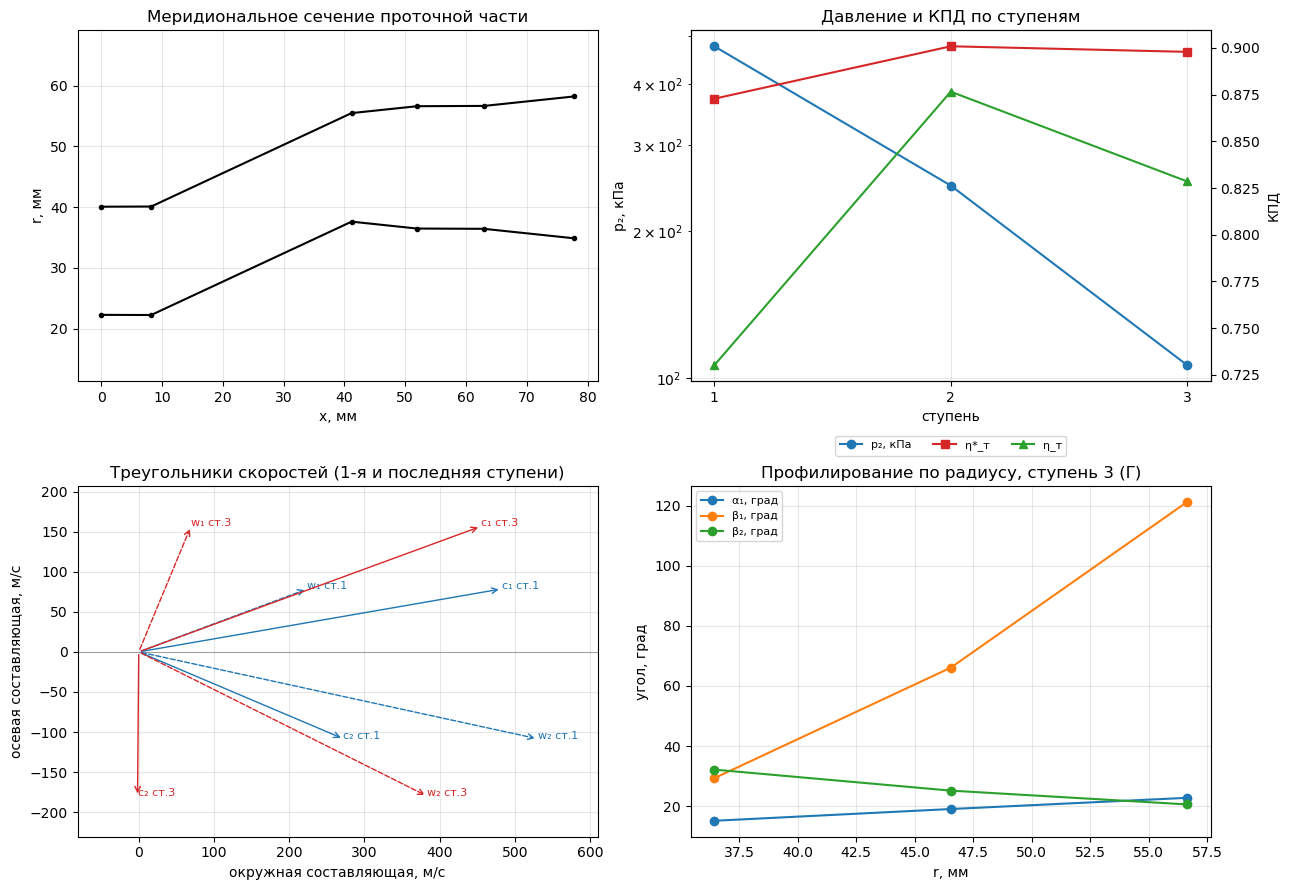

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]  # меридиональное сечение
a.plot(контур_df.x * 1e3, контур_df.r_н * 1e3, "k-o", ms=3)
a.plot(контур_df.x * 1e3, контур_df.r_в * 1e3, "k-o", ms=3)
a.set(xlabel="x, мм", ylabel="r, мм", title="Меридиональное сечение проточной части")
a.set_aspect("equal", adjustable="datalim")
a.grid(alpha=0.3)
a = ax[0, 1]  # давление и КПД по ступеням
ид = np.arange(1, z + 1)
л_p, = a.plot(ид, [s["p2"] / 1e3 for s in ступени], "o-", color="tab:blue", label="p₂, кПа")
a.set(xlabel="ступень", ylabel="p₂, кПа", title="Давление и КПД по ступеням", xticks=ид)
a.set_yscale("log")
a2 = a.twinx()
л_1, = a2.plot(ид, [s["η_т_п"] for s in ступени], "s-", color="tab:red", label="η*_т")
л_2, = a2.plot(ид, [s["η_т"] for s in ступени], "^-", color="tab:green", label="η_т")
a2.set_ylabel("КПД")
a.legend(handles=[л_p, л_1, л_2], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)
a.grid(alpha=0.3)
a = ax[1, 0]  # треугольники скоростей
точки = [(0.0, 0.0)]
for idx, цвет in ((0, "tab:blue"), (z - 1, "tab:red")):
    s = ступени[idx]
    for vx, vy, лаб, ls in ((s["c1u"], s["c1a"], "c₁", "-"), (s["c1u"] - s["u1"], s["c1a"], "w₁", "--"),
                            (s["c2u"], -s["c2a"], "c₂", "-"), (s["c2u"] + s["u2"], -s["c2a"], "w₂", "--")):
        a.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=цвет, ls=ls))
        a.text(vx, vy, f"{лаб} ст.{idx+1}", color=цвет, fontsize=8)
        точки.append((vx, vy))
a.plot(*zip(*точки), ".", alpha=0)  # для автомасштаба
a.margins(0.15)
a.set(xlabel="окружная составляющая, м/с", ylabel="осевая составляющая, м/с", title="Треугольники скоростей (1-я и последняя ступени)")
a.axhline(0, color="gray", lw=0.5)
a.grid(alpha=0.3)
a = ax[1, 1]  # углы по радиусу в последней ступени
df = профили[закон_ст[-1]][-1]
for пар, цвет in (("α₁, град", "tab:blue"), ("β₁, град", "tab:orange"), ("β₂, град", "tab:green")):
    a.plot(df.loc["r, мм"], df.loc[пар], "-o", color=цвет, label=пар)
a.set(xlabel="r, мм", ylabel="угол, град", title=f"Профилирование по радиусу, ступень {z} ({закон_ст[-1]})")
a.legend(fontsize=8)
a.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 14. Экспорт в Excel
Все таблицы расчёта записываются в `Результаты_турбины.xlsx` (рядом с блокнотом): сводка, исходные данные и выбранные параметры
с пунктами книги, ступени (п. 70–129), турбина в целом (п. 146–153, итоговые КПД и мощности — формулами Excel), проточная часть,
профилирование, решётки, проверки. Перезапустите блокнот — файл перезапишется по текущим параметрам.

In [18]:
import re

import io

from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference, Series
from openpyxl.chart.label import DataLabelList
from openpyxl.drawing.image import Image as XLImage
from openpyxl.worksheet.pagebreak import Break
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.properties import PageSetupProperties

файл_excel = Path("Результаты_турбины.xlsx")
ШРИФТ = "Arial"
_тонкая = Side(style="thin", color="BFBFBF")
РАМКА = Border(left=_тонкая, right=_тонкая, top=_тонкая, bottom=_тонкая)
ШАПКА = PatternFill("solid", fgColor="1F4E78")
РАЗДЕЛ = PatternFill("solid", fgColor="D9E1F2")
ВВОД = PatternFill("solid", fgColor="FFF2CC")
ОТСТУП = PatternFill("solid", fgColor="FCE4D6")


def формат(v):
    # числовой формат по величине числа (одинаковый для строки или столбца)
    a = abs(float(v))
    if a == 0 or a >= 1000 or (float(v).is_integer() and a < 1e6):
        return "0"
    if a < 1e-3:
        return "0.00E+00"
    return "0.0" if a >= 100 else "0.00" if a >= 10 else "0.000" if a >= 1 else "0.0000"


def формат_точно(v):
    # для заданных параметров: столько знаков, сколько у числа есть (0,9 -> «0,9», а не «0,9000»)
    a = abs(float(v))
    if 0 < a < 1e-3:
        return "0.00E+00"
    макс_d = len(формат(v).partition(".")[2])  # не точнее, чем формат по величине
    for d in range(0, макс_d + 1):
        if abs(float(v) - round(float(v), d)) < 1e-9 * max(1.0, a):
            return "0" if d == 0 else "0." + "0" * d
    return формат(v)


def запятая(т):
    # десятичная запятая в текстовых значениях, как у чисел Excel (номера пунктов «п. 6.2» не трогаем)
    т = т.replace("<=", "≤").replace(">=", "≥").replace("->", "→")
    return re.sub(r"(?<!п\. )(\d)\.(\d)", r"\1,\2", т)


def числовой_текст(т):
    return any(ch.isdigit() for ch in т) and bool(re.fullmatch(r"[\d\s.,/+\-–…°<=>≤≥]+", т))


def число(v):
    return isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool)


class Лист:
    # лист с текущей строкой и учётом ширины столбцов
    def __init__(self, wb, имя, заголовок_, пояснение=None, первый=False):
        self.ws = wb.active if первый else wb.create_sheet(имя)
        self.ws.title = имя
        self.ws.sheet_view.showGridLines = False
        self.ширина = {}
        self.ws.cell(row=1, column=1, value=заголовок_).font = Font(name=ШРИФТ, size=14, bold=True, color="1F4E78")
        if пояснение:
            self.ws.cell(row=2, column=1, value=пояснение).font = Font(name=ШРИФТ, size=9, italic=True, color="595959")
        self.r = 4

    def учесть(self, c, длина):
        self.ширина[c] = max(self.ширина.get(c, 0), длина)

    def ячейка(self, c, v, жирный=False, цвет=None, заливка=None, фмт=None, вправо=None):
        if isinstance(v, np.generic):
            v = v.item()
        if isinstance(v, str) and not v.startswith("="):
            v = запятая(v)
        x = self.ws.cell(row=self.r, column=c, value=v)
        x.font = Font(name=ШРИФТ, size=10, bold=жирный, color=цвет)
        x.border = РАМКА
        if заливка:
            x.fill = заливка
        if число(v) or фмт:
            x.number_format = фмт or формат(v)
        справа = вправо if вправо is not None else (число(v) or (isinstance(v, str) and (v.startswith("=") or числовой_текст(v))))
        x.alignment = Alignment(horizontal="right" if справа else "left", vertical="center", wrap_text=isinstance(v, str) and len(v) > 34)
        self.учесть(c, 11 if число(v) or (isinstance(v, str) and v.startswith("=")) else len(str(v)) + 2)
        return x

    def подпись(self, текст):
        self.r += 1
        self.ws.cell(row=self.r, column=1, value=текст).font = Font(name=ШРИФТ, size=11, bold=True, color="1F4E78")
        self.r += 1

    def шапка(self, имена):
        for c, имя in enumerate(имена, 1):
            имя = запятая(str(имя))
            x = self.ws.cell(row=self.r, column=c, value=имя)
            x.font = Font(name=ШРИФТ, size=10, bold=True, color="FFFFFF")
            x.fill = ШАПКА
            x.border = РАМКА
            x.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
            self.учесть(c, min(len(str(имя)), 16) + 2)  # длинные шапки переносятся, а не расширяют столбец
        self.ws.row_dimensions[self.r].height = 30
        self.r += 1

    def раздел(self, текст, ширина, заливка=РАЗДЕЛ):
        self.ws.merge_cells(start_row=self.r, start_column=1, end_row=self.r, end_column=ширина)
        x = self.ws.cell(row=self.r, column=1, value=текст)
        x.font = Font(name=ШРИФТ, size=10, bold=True, color="1F4E78")
        x.fill = заливка
        x.alignment = Alignment(vertical="center")
        for c in range(1, ширина + 1):
            self.ws.cell(row=self.r, column=c).border = РАМКА
        self.r += 1

    def текст(self, строки, ширина, заливки=None):
        # длинные строки - на всю ширину таблицы с переносом
        симв = sum(self.ширина.get(c, 10) for c in range(1, ширина + 1)) * 1.1
        for i, т in enumerate(строки):
            т = запятая(т)
            self.ws.merge_cells(start_row=self.r, start_column=1, end_row=self.r, end_column=ширина)
            x = self.ws.cell(row=self.r, column=1, value=т)
            x.font = Font(name=ШРИФТ, size=10, bold=т.startswith("ОТСТУПЛЕНИЕ"))
            x.alignment = Alignment(wrap_text=True, vertical="top")
            if заливки and заливки[i]:
                x.fill = заливки[i]
            for c in range(1, ширина + 1):
                self.ws.cell(row=self.r, column=c).border = РАМКА
            self.ws.row_dimensions[self.r].height = 14 * max(1, math.ceil(len(т) / max(симв, 40)))
            self.r += 1

    def строки_таблицы(self, строки_, по_строкам=True, ввод=()):
        # строки_: список кортежей; формат чисел - общий на строку (по_строкам) или на столбец
        фмт_ст = {}
        if not по_строкам:
            for c in range(len(строки_[0]) if строки_ else 0):
                чис = [abs(float(s[c])) for s in строки_ if число(s[c])]
                if чис:
                    фмт_ст[c] = формат(max(чис)) if not all(float(v).is_integer() for v in чис) else "0"
        for s in строки_:
            чис = [abs(float(v)) for v in s if число(v)]
            if len(чис) == 1:
                фмт_стр = формат_точно(next(v for v in s if число(v)))
            else:
                фмт_стр = (формат(max(чис)) if not all(float(v).is_integer() for v in чис) else "0") if чис else None
            for c, v in enumerate(s, 1):
                self.ячейка(c, v, фмт=(фмт_стр if по_строкам else фмт_ст.get(c - 1)) if число(v) else None,
                            заливка=ВВОД if c in ввод else None)
            self.r += 1

    def готово(self, мин=6, макс=48, альбом=None):
        for c, w in self.ширина.items():
            self.ws.column_dimensions[get_column_letter(c)].width = max(мин, min(макс, w))
        ws = self.ws
        ws.sheet_properties.pageSetUpPr = PageSetupProperties(fitToPage=True)
        ws.page_setup.fitToWidth = 1
        ws.page_setup.fitToHeight = 0
        ws.page_setup.paperSize = ws.PAPERSIZE_A4
        общая = sum(max(мин, min(макс, w)) for w in self.ширина.values())
        ws.page_setup.orientation = "landscape" if (альбом if альбом is not None else общая > 95) else "portrait"
        ws.page_margins.left = ws.page_margins.right = 0.4
        ws.page_margins.top = ws.page_margins.bottom = 0.5
        ws.print_options.horizontalCentered = True


def вставить_рисунок(л, fig, ширина_px):
    # рисунок matplotlib -> PNG в ячейку A{л.r}; строки сдвигаются на высоту рисунка
    буф = io.BytesIO()
    fig.savefig(буф, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    буф.seek(0)
    img = XLImage(буф)
    k = ширина_px / img.width
    img.width, img.height = ширина_px, img.height * k
    л.ws.add_image(img, f"A{л.r}")
    л.r += math.ceil(img.height / 20) + 2


def разрыв(л):
    # разрыв страницы при печати перед графиками/рисунками
    л.ws.row_breaks.append(Break(id=л.r - 1))  # разрыв после предыдущей строки
    л.r += 1


def вставить_график(л, график, ширина_см=16, высота_см=7.0):
    график.width, график.height = ширина_см, высота_см
    л.ws.add_chart(график, f"A{л.r}")
    л.r += math.ceil(высота_см * 37.8 / 20) + 2


def столбчатый(заголовок_, ось_y, ряды, категории, подписи="0.000", y_макс=None):
    # ряды: [(название, Reference)]
    ch = BarChart()
    ch.type = "col"
    ch.title = f"{заголовок_}, {ось_y}" if ось_y not in ("-", "КПД", "π") else заголовок_
    ch.style = 10
    ch.title.overlay = False
    for имя, ref in ряды:
        ряд = Series(ref, title=имя)
        ch.series.append(ряд)
    ch.set_categories(категории)
    ch.dataLabels = DataLabelList()
    ch.dataLabels.showVal = True
    ch.dataLabels.showSerName = False
    ch.dataLabels.showCatName = False
    ch.dataLabels.showLegendKey = False
    ch.dataLabels.showPercent = False
    ch.dataLabels.numFmt = подписи
    ch.y_axis.numFmt = подписи
    ch.y_axis.majorGridlines = None
    ch.y_axis.delete = False
    ch.x_axis.delete = False
    ch.varyColors = False
    if len(ряды) > 1:
        ch.legend.position = "r"
        ch.legend.overlay = False
    else:
        ch.legend = None
    if y_макс is not None:
        ch.y_axis.scaling.min = 0
        ch.y_axis.scaling.max = y_макс
    return ch


def рисунок_проточной_части():
    # меридиональное сечение: контур, венцы СА (синие) и РК (оранжевые) с длинами лопаток
    xs, rн, rв = (контур_df.x * 1e3).values, (контур_df.r_н * 1e3).values, (контур_df.r_в * 1e3).values
    сеч = list(контур_df.сечение)
    fig, ax = plt.subplots(figsize=(10, 4.6))
    for i, (s_, g) in enumerate(zip(ступени, геом), 1):
        for имя, b, l, цвет in ((f"СА{i}", g["b_c"], s_["l_c"], "#9DC3E6"), (f"РК{i}", g["b_л"], s_["l_л"], "#F4B183")):
            x1 = xs[сеч.index(f"{имя} выход")]
            x0 = x1 - b * 1e3
            rn0, rn1 = np.interp([x0, x1], xs, rн)
            rv0, rv1 = np.interp([x0, x1], xs, rв)
            ax.fill([x0, x1, x1, x0], [rv0, rv1, rn1, rn0], color=цвет, ec="0.3", lw=0.8)
            ax.text((x0 + x1) / 2, (rn1 + rv1) / 2, f"{имя}\n{l*1e3:.1f}".replace(".", ","), ha="center", va="center", fontsize=7.5, weight="bold")
    x_min = xs[0] - геом[0]["b_c"] * 1e3
    ax.plot(np.r_[x_min, xs], np.r_[rн[0], rн], "k-", lw=1.6)
    ax.plot(np.r_[x_min, xs], np.r_[rв[0], rв], "k-", lw=1.6)
    ax.axhline(0, color="0.4", ls="-.", lw=0.8)
    ax.text(x_min, 1, "ось ротора", fontsize=7, color="0.4", va="bottom")
    ax.annotate("газ", xy=(x_min - 1, (rн[0] + rв[0]) / 2), xytext=(x_min - 9, (rн[0] + rв[0]) / 2),
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.4), color="tab:red", fontsize=8, va="center", ha="right")
    ax.text(xs[-1], -1.5, "числа в венцах - длина лопатки, мм", fontsize=7, color="0.35", ha="right", va="top")
    ax.set_aspect("equal")
    ax.set_ylim(-5, rн.max() + 5)
    ax.set_xlim(x_min - 16, xs[-1] + 6)
    ax.set_xlabel("x, мм")
    ax.set_ylabel("r, мм")
    ax.set_title(f"Проточная часть (меридиональное сечение): z = {z}, D_т = {D_т*1e3:.1f} мм, n = {n_т:.0f} об/мин".replace(".", ","), fontsize=10)
    ax.grid(alpha=0.25)
    return fig


def рисунок_треугольников():
    fig, ax = plt.subplots(z, 1, figsize=(8, 3.0 * z))
    for a, (i, s_) in zip(np.atleast_1d(ax), enumerate(ступени, 1)):
        for vx, vy, лаб, цвет, ls in ((s_["c1u"], s_["c1a"], "c₁", "tab:blue", "-"), (s_["c1u"] - s_["u1"], s_["c1a"], "w₁", "tab:blue", "--"),
                                      (s_["c2u"], -s_["c2a"], "c₂", "tab:red", "-"), (s_["c2u"] + s_["u2"], -s_["c2a"], "w₂", "tab:red", "--")):
            a.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=цвет, ls=ls, lw=1.4))
            a.text(vx, vy, f" {лаб}", color=цвет, fontsize=11, weight="bold")
        a.plot([s_["c1u"] - s_["u1"], s_["c1u"]], [s_["c1a"]] * 2, "k-", lw=0.8)
        a.plot([s_["c2u"], s_["c2u"] + s_["u2"]], [-s_["c2a"]] * 2, "k-", lw=0.8)
        a.text(s_["c1u"] - s_["u1"] / 2, s_["c1a"] * 1.08, "u₁", fontsize=8, ha="center")
        a.axhline(0, color="0.5", lw=0.5)
        a.axvline(0, color="0.5", lw=0.5)
        a.set_title(f"Ступень {i}: α₁ = {s_['α1']:.1f}°, α₂ = {s_['α2']:.1f}°".replace(".", ","), fontsize=9)
        a.set_ylabel("c_a, м/с")
        a.margins(0.12)
        a.grid(alpha=0.25)
    np.atleast_1d(ax)[-1].set_xlabel("окружная составляющая c_u, м/с (вверх - вход в РК, вниз - выход из РК)")
    fig.suptitle("Треугольники скоростей на среднем радиусе", fontsize=11)
    fig.tight_layout()
    return fig


def рисунок_профилирования():
    fig, ax = plt.subplots(z, 1, figsize=(8, 2.8 * z), sharey=False)
    for a, (i, м) in zip(np.atleast_1d(ax), enumerate(закон_ст, 1)):
        df = профили[м][i - 1]
        r_ = df.loc["r, мм"].values
        for пар, цвет in (("α₁, град", "tab:blue"), ("β₁, град", "tab:orange"), ("α₂, град", "tab:green"), ("β₂, град", "tab:red")):
            a.plot(df.loc[пар].values, r_, "-o", color=цвет, ms=4, label=пар.split(",")[0])
        a.set_title(f"Ступень {i} ({'Γ = const' if м == 'Γ' else 'α₁ = const'})", fontsize=10)
        a.set_ylabel("r, мм")
        a.grid(alpha=0.25)
        a.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
    np.atleast_1d(ax)[-1].set_xlabel("угол потока, град")
    fig.suptitle("Углы потока по радиусу (корень - средний - периферия)", fontsize=10)
    fig.tight_layout()
    return fig


wb = Workbook()
отступления = [т for т in зам if т.startswith("ОТСТУПЛЕНИЕ")]
прочие = [т for т in зам if not т.startswith("ОТСТУПЛЕНИЕ")]

# ================= Сводка =================
л = Лист(wb, "Сводка", f"Проточная часть газовой турбины ТВД: z = {z}, π*к = {π_к:.0f}, N_в = {N_зад/1e3:.0f} кВт",
         "Михальцев В.Е., Моляков В.Д. «Теория и проектирование газовой турбины», ч. 1 - порядок расчёта п. 1-153. "
         "Источник чисел: Main_Turbinis_Calc_Book.ipynb", первый=True)
л.шапка(["величина", "ед.", "значение"])
for раздел_, группа in сводка_df.reset_index().groupby("раздел", sort=False):
    л.раздел(раздел_, 3)
    л.строки_таблицы([(в, е, з_) for _, в, е, з_ in группа.itertuples(index=False)])
л.учесть(1, 42)
if отступления:
    л.подпись("Отступления от рекомендаций книги и цикла")
    л.текст(отступления, 3, [ОТСТУП] * len(отступления))
л.подпись("Замечания")
л.текст(прочие or ["замечаний нет"], 3)
разрыв(л)
л.подпись("Вид проточной части")
вставить_рисунок(л, рисунок_проточной_части(), 620)
л.ws.freeze_panes = "A5"
л.готово(альбом=False)

# ================= Исходные данные =================
л = Лист(wb, "Исходные данные", "Исходные данные и выбранные параметры",
         "Значения меняются в блокноте (раздел 2) - этот лист их только показывает. Жёлтым - параметры, выбранные проектировщиком.")
л.шапка(["пункт", "параметр", "значение", "ед.", "рекомендация книги / источник"])
л.раздел("Из расчёта цикла (Turbinis-Cycle)", 5)
л.строки_таблицы([("—", в, з_, е, "цикл") for в, е, з_ in табл_исх.itertuples(index=False)])
л.раздел("Выбранные параметры (раздел 2 блокнота)", 5)
л.строки_таблицы([
    ("п. 5", "η_л для оценки T_т", η_л_ожид, "-", "задаётся"),
    ("п. 8", "c_т.a - осевая скорость за турбиной (1-е приближение)", c_та, "м/с", "из цикла, уточняется расчётом"),
    ("п. 10", "σ_л - допустимое напряжение в рабочих лопатках", σ_л, "МПа", "u_т = 300...400 м/с (стр. 59)"),
    ("п. 11", "k_n - коэффициент формы лопатки", k_n, "-", "≈ 6,8·10⁻⁶ (стр. 56)"),
    ("п. 45", "l_т/D_т последней ступени", l_т_D_т, "-", "≤ 1/3,5...1/3 (стр. 58)"),
    ("п. 51", "y₀ = (u/c₀)опт - для оценки z", y0, "-", "0,55...0,6 при ρ = 0,25...0,45 (стр. 58)"),
    ("п. 53", "μ - использование c₂ следующей ступенью", μ, "-", "выбирается"),
    ("п. 54", "z - число ступеней", z, "-", f"по формуле п. 54: {z_расч:.2f}"),
    ("п. 37", "φ - коэффициент скорости СА", φ, "-", "0,95...0,97 (стр. 34)"),
    ("п. 89", "ψ - коэффициент скорости РК", ψ, "-", "книга чисел не даёт; типично 0,92...0,96"),
    ("гл. 8", "ζ_тр СА / РК - трение на профиле (уточнение φ, ψ)", f"{ζ_тр_c} / {ζ_тр_л}", "-", "по графику 0,016...0,019"),
    ("п. 113", "δ_л/l - относительный радиальный зазор", δ_отн, "-", "0,007...0,01 (стр. 63)"),
    ("п. 113", "δ_мин - наименьший радиальный зазор", δ_мин * 1e3, "мм", "соты ≤ 0,2 мм (стр. 12)"),
    ("п. 119", "ε - степень парциальности", ε_парц, "-", "полный подвод"),
    ("п. 65-66", "l/b_a СА / РК (исходное)", f"{lb_c} / {lb_л}", "-", "2...2,5 и 2,5...3 (стр. 61)"),
    ("п. 67-68", "δ_a/b_a - осевой зазор", δа_к_ba, "-", "0,20...0,25 (стр. 62)"),
], ввод=(3,))
л.раздел("Параметры по ступеням (ст. 1 / ст. 2 / ...)", 5)
по_ст = lambda x, f="{:g}": " / ".join(f.format(v) for v in x)
л.строки_таблицы([
    ("п. 48", "D/D_т - средний диаметр ступени", по_ст(D_ст), "-", "меньше D - длиннее лопатка, но меньше u"),
    ("п. 55", "веса распределения π", по_ст(π_веса), "-", "ln(p*₀/p₂) ступени ~ вес"),
    ("п. 58", "α₁ - угол выхода из СА", по_ст(α1_ст), "град", "малые турбины 11...14° (стр. 34-35)"),
    ("п. 96", "κ = c₂a/c₁a", по_ст(κ_ст), "-", "выбирается"),
    ("гл. 7", "закон профилирования", " / ".join("Γ" if м == "Γ" else "α₁" for м in закон_ст), "-", "Γ = const или α₁ = const (разд. 7.3)"),
], ввод=(3,))
л.раздел("Ограничения", 5)
л.строки_таблицы([
    ("п. 99", "α₂ промежуточных ступеней", f"{α2_пром[0]:.0f}...{α2_пром[1]:.0f}", "град", "стр. 38"),
    ("п. 99", "α₂ последней ступени", f"{α2_посл[0]:.0f}...{α2_посл[1]:.0f}", "град", "стр. 38"),
    ("п. 99", "α₂ 1-й ступени", f"{α2_ст1[0]:.0f}...{α2_ст1[1]:.0f}", "град", "ослаблен по решению (книга: 70...90°)"),
    ("—", "π = p*₀/p₂ ступени", f"{π_ст_мин}...{π_ст_макс}", "-", "выше 2,4 - запирание"),
    ("п. 56", "ρ у корня, не менее", ρ_корня_мин, "-", "0,05...0,1 (стр. 58)"),
    ("п. 69", "угол раскрытия, не более", γ_макс, "град", f"желательно {γ_цель:.0f}° (стр. 56)"),
    ("—", "l_с1, не менее", l_c1_мин * 1e3, "мм", "требование"),
], ввод=(3,))
for c in (3,):
    for row in л.ws.iter_rows(min_row=5, max_row=л.r, min_col=c, max_col=c):
        for x in row:
            if isinstance(x.value, str):
                x.alignment = Alignment(horizontal="right", vertical="center")
л.готово()

# ================= Ступени =================
л = Лист(wb, "Ступени", "Расчёт ступеней на среднем радиусе (п. 63-129)", "Порядок строк - как в порядке расчёта книги")
л.шапка(["пункт", "величина", "ед."] + [f"ступень {i}" for i in range(1, z + 1)])
r_шапки = л.r - 1
разделы_ст = [(83, "Сопловой аппарат (п. 48-83)"), (100, "Рабочее колесо (п. 84-100)"), (123, "Работа и потери (п. 101-123)"), (999, "За ступенью (п. 124-129)")]
стр_ст, текущий = {}, None
for п, н, е, к, м in строки:
    номер = int(п.split()[1]) if п.startswith("п.") else 0
    имя_р = next(t for предел, t in разделы_ст if номер <= предел)
    if имя_р != текущий:
        л.раздел(имя_р, 3 + z)
        текущий = имя_р
    стр_ст[к] = л.r
    л.строки_таблицы([(п, н, е, *[s[к] * м for s in ступени])])
кат = Reference(л.ws, min_col=4, max_col=3 + z, min_row=r_шапки)
ряд = lambda к: Reference(л.ws, min_col=4, max_col=3 + z, min_row=стр_ст[к])
разрыв(л)
л.подпись("Графики по ступеням")
вставить_график(л, столбчатый("КПД ступеней", "КПД", [("η_т (п. 122)", ряд("η_т")), ("η*_т (п. 129)", ряд("η_т_п"))], кат))
вставить_график(л, столбчатый("Степень понижения давления π = p*₀/p₂ (допуск 1,8...2,4)", "π", [("π", ряд("π_ст"))], кат, "0.00", y_макс=π_ст_макс + 0.2))
разрыв(л)
вставить_график(л, столбчатый("Длины лопаток", "мм", [("l_с - сопловая (п. 63)", ряд("l_c")), ("l_л - рабочая (п. 95)", ряд("l_л"))], кат, "0.0"))
вставить_график(л, столбчатый("Угол выхода из ступени α₂ (90° - осевой выход)", "град", [("α₂ (п. 99)", ряд("α2"))], кат, "0.0", y_макс=100))
разрыв(л)
л.подпись("Треугольники скоростей")
вставить_рисунок(л, рисунок_треугольников(), 600)
л.ws.freeze_panes = f"D{r_шапки + 1}"
л.готово(альбом=False)

# ================= Турбина =================
л = Лист(wb, "Турбина", "Параметры турбины в целом (п. 146-153) и сверка с циклом",
         "Синие числа - результаты расчёта ступеней; итоговые КПД и мощности - формулы Excel")
л.шапка(["пункт", "величина", "ед.", "значение", "примечание"])
адрес = {}


def строка_т(ключ, пункт, имя, ед, значение, пояснение, фмт, ввод=False):
    for c, v in enumerate([пункт, имя, ед], 1):
        л.ячейка(c, v)
    л.ячейка(4, значение, цвет="0000FF" if ввод else None, фмт=фмт, жирный=not ввод)
    л.ячейка(5, пояснение)
    адрес[ключ] = f"D{л.r}"
    л.r += 1


кол_ст = [get_column_letter(4 + i) for i in range(z)]
л.раздел("Исходные величины", 5)
for i, s in enumerate(ступени, 1):
    строка_т(f"g{i}", "п. 136", f"g_{i} = G_c{i}/G_c1", "-", s["G_c"] / G_c1, "отношение расходов через СА", "0.0000", True)
строка_т("H", "п. 147", "H_т - располагаемый теплоперепад", "кДж/кг", H_т / 1e3, "по статическому p_т (п. 4)", "0.0", True)
строка_т("Hп", "п. 150", "H*_т - теплоперепад по параметрам торможения", "кДж/кг", H_т_полн / 1e3, "до p*_т", "0.0", True)
строка_т("hв", "п. 149", "h_вz = c₂z²/2", "кДж/кг", h_вz / 1e3, "потеря с выходной скоростью", "0.00", True)
строка_т("G1", "—", "G_c1 - расход через СА 1-й ступени", "кг/с", G_c1, "", "0.0000", True)
строка_т("Gв", "—", "G_в - расход воздуха", "кг/с", G_в, "подобран под N_в", "0.0000", True)
строка_т("ηм", "п. 152", "η_м - механический КПД", "-", η_м, "цикл", "0.0000", True)
строка_т("ηр", "—", "η_р - КПД редуктора", "-", η_р, "цикл", "0.000", True)
строка_т("Lк", "—", "L_к - работа компрессора", "кДж/кг", L_к / 1e3, "цикл", "0.0", True)
л.раздел("Итог (формулы)", 5)
L_ф = "+".join(f"{адрес[f'g{i+1}']}*'Ступени'!{кол_ст[i]}{стр_ст['L_т']}" for i in range(z))
строка_т("L", "п. 146", "L_тΣ = Σ g_i·L_т i", "кДж/кг", f"={L_ф}", "L_т i - лист «Ступени», п. 124", "0.0")
строка_т("ηт", "п. 148", "η_т = L_тΣ/H_т", "-", f"={адрес['L']}/{адрес['H']}", "мощностной КПД", "0.0000")
строка_т("ηл", "п. 149", "η_л = (L_тΣ + h_вz)/H_т", "-", f"=({адрес['L']}+{адрес['hв']})/{адрес['H']}", "лопаточный КПД", "0.0000")
строка_т("ηп", "п. 151", "η*_т = L_тΣ/H*_т", "-", f"={адрес['L']}/{адрес['Hп']}", "КПД по параметрам торможения", "0.0000")
строка_т("N", "п. 153", "N_т = L_тΣ·G_c1·η_м", "кВт", f"={адрес['L']}*{адрес['G1']}*{адрес['ηм']}", "мощность турбины", "0.0")
строка_т("Nв", "—", "N_в = (N_т - G_в·L_к)·η_р", "кВт", f"=({адрес['N']}-{адрес['Gв']}*{адрес['Lк']})*{адрес['ηр']}", f"задано {N_зад/1e3:.0f} кВт", "0.0")
л.подпись("Сверка с циклом")
л.шапка(["", "величина", "ед.", "расчёт по книге", "цикл", "расхождение, %"])
for имя, (a_, b_) in zip(сверка.index, сверка.iloc[:, :2].itertuples(index=False)):
    имя_, _, ед_ = имя.rpartition(", ")
    л.ячейка(1, "")
    л.ячейка(2, имя_ or имя)
    л.ячейка(3, ед_ if имя_ else "-")
    л.ячейка(4, float(a_), цвет="0000FF")
    л.ячейка(5, float(b_), цвет="0000FF", фмт=формат(float(a_)))
    л.ячейка(6, f"=IF(E{л.r}=0,0,(D{л.r}/E{л.r}-1)*100)", фмт="+0.0;-0.0;0.0")
    л.r += 1
л.готово(альбом=False)

# ================= Проточная часть =================
л = Лист(wb, "Проточная часть", "Меридиональное сечение и угол раскрытия (п. 63-69)",
         "γ_н, γ_в и γ по участкам - формулы Excel по координатам сечений")
л.шапка(["величина", "ед.", "значение", "норма"])
л.строки_таблицы([
    ("длина проточной части", "мм", dx_т * 1e3, ""),
    ("угол раскрытия турбины в целом γ (п. 69)", "град", γ_турб, f"желательно {γ_цель:.0f}°"),
    ("наибольший угол раскрытия на участке", "град", γ_max, f"≤ {γ_макс:.0f}° (стр. 56)"),
], по_строкам=True)
л.подпись("Длины и ширины венцов (п. 63-68)")
л.шапка(["ступень", "l_с СА, мм", "b_a СА, мм", "l/b_a СА", "l_л РК, мм", "b_a РК, мм", "l/b_a РК"])
л.строки_таблицы([(i, *row) for i, row in zip(ширины_df.index, ширины_df.itertuples(index=False))], по_строкам=False)
л.подпись("Сечения по ходу газа")
л.шапка(["сечение", "x, мм", "r наружный, мм", "r внутренний, мм", "γ_н, град", "γ_в, град", "γ = γ_н + γ_в, град", "участок"])
r1 = л.r
for i, (имя, x, rн, rв) in enumerate(контур_df[["сечение", "x", "r_н", "r_в"]].itertuples(index=False)):
    л.ячейка(1, имя)
    for c, v in ((2, x * 1e3), (3, rн * 1e3), (4, rв * 1e3)):
        л.ячейка(c, v, фмт="0.00")
    if i == 0:
        for c in (5, 6, 7, 8):
            л.ячейка(c, "—", вправо=True)
    else:
        rr = л.r
        л.ячейка(5, f"=DEGREES(ATAN((C{rr}-C{rr-1})/(B{rr}-B{rr-1})))", фмт="0.0")
        л.ячейка(6, f"=DEGREES(ATAN((D{rr-1}-D{rr})/(B{rr}-B{rr-1})))", фмт="0.0")
        л.ячейка(7, f"=E{rr}+F{rr}", фмт="0.0", жирный=True)
        л.ячейка(8, f"{контур_df.сечение[i-1].split()[0]} → {имя.split()[0]}")
    л.r += 1
л.учесть(1, 40)
n_уч = len(контур_df) - 1
разрыв(л)
л.подпись("Углы раскрытия по участкам")
вставить_график(л, столбчатый(f"Угол раскрытия γ по участкам (желательно {γ_цель:.0f}°, не более {γ_макс:.0f}°)", "град",
                              [("γ = γ_н + γ_в", Reference(л.ws, min_col=7, min_row=r1 + 1, max_row=r1 + n_уч))],
                              Reference(л.ws, min_col=8, min_row=r1 + 1, max_row=r1 + n_уч), "0.0", y_макс=γ_макс + 2))
л.подпись("Вид проточной части")
вставить_рисунок(л, рисунок_проточной_части(), 700)
л.готово(альбом=False)

# ================= Профилирование =================
л = Лист(wb, "Профилирование", "Профилирование лопаток по радиусу (гл. 7)", "Корень / средний радиус / периферия")
л.шапка(["ступень", "закон", "α₁ у корня, град", "ρ у корня", f"α₁к ≥ {α1_мин_корня:.0f}°, ρк ≥ {ρ_корня_мин}"])
for ст_, закон_, а, р_, ст_ус in табл_корень.itertuples(index=False):
    л.ячейка(1, ст_)
    л.ячейка(2, закон_)
    л.ячейка(3, а, фмт="0.0")
    л.ячейка(4, р_, фмт="0.000")
    л.ячейка(5, ст_ус, жирный=True, цвет="008000" if ст_ус == "выполнено" else "C00000")
    л.r += 1
л.подпись("Параметры по радиусу")
л.шапка(["параметр", "корень", "средний", "периферия"])
for i, м in enumerate(закон_ст, 1):
    л.раздел(f"Ступень {i} - закон {'Γ = const' if м == 'Γ' else 'α₁ = const'}", 4)
    df = профили[м][i - 1]
    л.строки_таблицы([(пар, *df.loc[пар].values) for пар in df.index])
л.учесть(1, 18)
разрыв(л)
л.подпись("Углы по радиусу")
вставить_рисунок(л, рисунок_профилирования(), 560)
л.готово(альбом=False)

# ================= Решётки =================
л = Лист(wb, "Решётки", "Решётки профилей (гл. 8)",
         "Отставание потока - стр. 78; хорда b = b_a/sin γ, t/b - стр. 82; толщина выходной кромки - стр. 80")
л.шапка(["параметр"] + [f"ступень {i}" for i in range(1, z + 1)])
половина = len(решётки_df.index) // 2
for j, имя in enumerate(решётки_df.index):
    if j in (0, половина):
        л.раздел("Сопловая решётка" if j == 0 else "Рабочая решётка", 1 + z)
    л.строки_таблицы([(имя, *решётки_df.loc[имя].values)])
л.учесть(1, 22)
л.готово(альбом=False)

# ================= Проверки =================
л = Лист(wb, "Проверки", "Проверки расчёта", "Все проверки должны иметь статус «выполнено»")
л.шапка(["проверка", "значение", "допуск", "статус"])
for что, знач, доп, ст_ус in табл_проверок.itertuples(index=False):
    л.ячейка(1, что)
    л.ячейка(2, знач, вправо=True)
    л.ячейка(3, доп, вправо=False)
    л.ячейка(4, ст_ус, жирный=True, цвет="008000" if ст_ус == "выполнено" else "C00000")
    л.r += 1
л.ширина[2] = min(л.ширина[2], 30)
if отступления:
    л.подпись("Отступления")
    л.текст(отступления, 4, [ОТСТУП] * len(отступления))
л.подпись("Замечания")
л.текст(прочие or ["замечаний нет"], 4)
л.готово(альбом=False)

wb.calculation.fullCalcOnLoad = True  # формулы Excel пересчитает при открытии
wb.save(файл_excel)
print(f"Записан {файл_excel.resolve()}: листы " + ", ".join(wb.sheetnames))

Записан /home/jovyan/work/Turbinis-Curs/Turbinis-Calc/Результаты_турбины.xlsx: листы Сводка, Исходные данные, Ступени, Турбина, Проточная часть, Профилирование, Решётки, Проверки
